## Phase 1: Data Integrity and Audit

In [1]:
# ============================================================
# PHASE 1 — DATA AUDIT (final correct version)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.signal import find_peaks

PATH = r"C:\MY_Files\DE\dcs_data_pipeline\Medallion\bronze_layer\master_data.parquet"
df   = pd.read_parquet(PATH)

FLIGHT_COL  = "mission_id"
MISSION_COL = "flight_data_mission_type"
BAND_COL    = "band_category"
BASELINE    = "baseline"

print(f"✅ Loaded — {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"   Mission types  : {sorted(df[MISSION_COL].unique())}")
print(f"   Band categories: {sorted(df[BAND_COL].unique())}")
print(f"   Unique flights : {df[FLIGHT_COL].nunique()}")

✅ Loaded — 1,540,913 rows × 38 columns
   Mission types  : ['baseline', 'dual_engine_fault', 'l_engine_fault', 'r_engine_fault']
   Band categories: ['baseline_1000ft_350kts', 'baseline_1000ft_400kts', 'baseline_1000ft_450kts', 'baseline_20000ft_350kts', 'baseline_20000ft_400kts', 'baseline_20000ft_450kts', 'baseline_8000ft_350kts', 'baseline_8000ft_400kts', 'baseline_8000ft_450kts', 'dual_engine_1000ft_350kts', 'dual_engine_1000ft_400kts', 'dual_engine_1000ft_450kts', 'dual_engine_20000ft_350kts', 'dual_engine_20000ft_400kts', 'dual_engine_20000ft_450kts', 'dual_engine_8000ft_350kts', 'dual_engine_8000ft_400kts', 'dual_engine_8000ft_450kts', 'l_engine_1000ft_350kts', 'l_engine_1000ft_400kts', 'l_engine_1000ft_450kts', 'l_engine_20000ft_350kts', 'l_engine_20000ft_400kts', 'l_engine_20000ft_450kts', 'l_engine_8000ft_350kts', 'l_engine_8000ft_400kts', 'l_engine_8000ft_450kts', 'r_engine_1000ft_350kts', 'r_engine_1000ft_400kts', 'r_engine_1000ft_450kts', 'r_engine_20000ft_350kts', 'r_engi

In [2]:
# ============================================================
# AUDIT 1 — SCHEMA & NULLS
# ============================================================

print("=" * 60)
print("AUDIT 1 — SCHEMA & NULL CHECK")
print("=" * 60)

audit1 = pd.DataFrame({
    "dtype"     : df.dtypes,
    "null_count": df.isna().sum(),
    "null_%"    : (df.isna().sum() / len(df) * 100).round(3)
})
display(audit1)

if df.isna().sum().sum() == 0:
    print("✅ No nulls in any column")
else:
    print(f"⚠️  Nulls found — see table above")

AUDIT 1 — SCHEMA & NULL CHECK


,dtype,null_count,null_%
id,int64,0,0.0
mission_id,str,0,0.0
ingest_time,"datetime64[us, UTC]",0,0.0
sensors_aoa,float64,0,0.0
sensors_tas,float64,0,0.0
sensors_vsi,float64,0,0.0
sensors_yaw,float64,0,0.0
sensors_mach,float64,0,0.0
sensors_roll,float64,0,0.0
sensors_pitch,float64,0,0.0


✅ No nulls in any column


In [3]:
# ============================================================
# AUDIT 2 — TIMESTAMP SANITY
# timestamp is already in seconds, starts at ~0.025s
# ============================================================

print("=" * 60)
print("AUDIT 2 — TIMESTAMP CHECK")
print("=" * 60)

print(f"  dtype          : {df['timestamp'].dtype}")
print(f"  global min     : {df['timestamp'].min():.3f}s")
print(f"  global max     : {df['timestamp'].max():.1f}s")

# Check starting timestamp per flight — should all start near 0.025
flight_start = df.groupby(FLIGHT_COL)["timestamp"].min()
print(f"\n  Flight start timestamps:")
print(f"    min : {flight_start.min():.3f}s")
print(f"    max : {flight_start.max():.3f}s")
print(f"    mean: {flight_start.mean():.3f}s")

if flight_start.max() - flight_start.min() < 1.0:
    print("\n✅ All flights start at consistent timestamp (~0.025s)")
else:
    print("\n⚠️  Flights have inconsistent start timestamps — investigate")

AUDIT 2 — TIMESTAMP CHECK
  dtype          : float64
  global min     : 0.025s
  global max     : 224.1s

  Flight start timestamps:
    min : 0.025s
    max : 0.060s
    mean: 0.028s

✅ All flights start at consistent timestamp (~0.025s)


AUDIT 3 — FLIGHT COUNTS


band_category,baseline_1000ft_350kts,baseline_1000ft_400kts,baseline_1000ft_450kts,baseline_20000ft_350kts,baseline_20000ft_400kts,baseline_20000ft_450kts,baseline_8000ft_350kts,baseline_8000ft_400kts,baseline_8000ft_450kts,dual_engine_1000ft_350kts,...,l_engine_8000ft_450kts,r_engine_1000ft_350kts,r_engine_1000ft_400kts,r_engine_1000ft_450kts,r_engine_20000ft_350kts,r_engine_20000ft_400kts,r_engine_20000ft_450kts,r_engine_8000ft_350kts,r_engine_8000ft_400kts,r_engine_8000ft_450kts
flight_data_mission_type,,,,,,,,,,,,,,,,,,,,,
baseline,17,17,17,17,17,17,17,17,17,0,...,0,0,0,0,0,0,0,0,0,0
dual_engine_fault,0,0,0,0,0,0,0,0,0,8,...,0,0,0,0,0,0,0,0,0,0
l_engine_fault,0,0,0,0,0,0,0,0,0,0,...,8,0,0,0,0,0,0,0,0,0
r_engine_fault,0,0,0,0,0,0,0,0,0,0,...,0,8,8,8,8,8,8,8,8,8



Total ticks per mission type:


,tick_count
flight_data_mission_type,
baseline,691721
dual_engine_fault,332227
l_engine_fault,253671
r_engine_fault,263294


C:\Users\jagad\AppData\Local\Temp\ipykernel_28092\1192549906.py:34: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


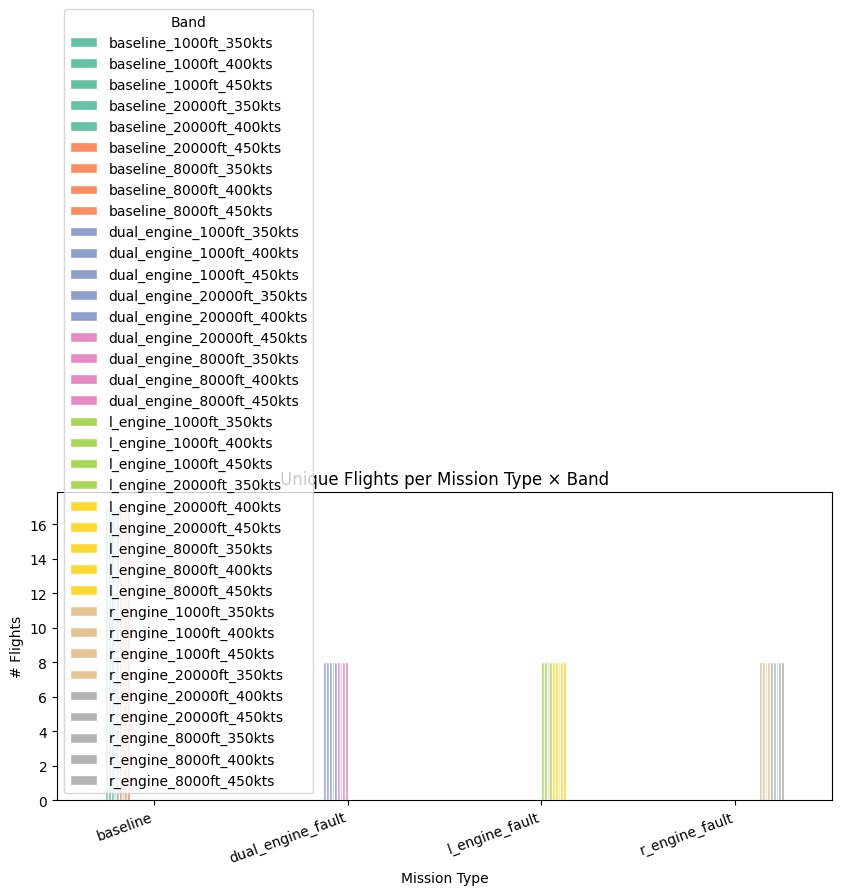

In [4]:
# ============================================================
# AUDIT 3 — FLIGHT COUNTS PER MISSION TYPE × BAND
# ============================================================

print("=" * 60)
print("AUDIT 3 — FLIGHT COUNTS")
print("=" * 60)

flight_counts = (
    df.groupby([MISSION_COL, BAND_COL])[FLIGHT_COL]
    .nunique()
    .reset_index()
    .rename(columns={FLIGHT_COL: "unique_flights"})
)

pivot = (
    flight_counts
    .pivot(index=MISSION_COL, columns=BAND_COL, values="unique_flights")
    .fillna(0)
    .astype(int)
)
display(pivot)

print("\nTotal ticks per mission type:")
display(df.groupby(MISSION_COL).size().rename("tick_count").to_frame())

fig, ax = plt.subplots(figsize=(10, 4))
pivot.plot(kind="bar", ax=ax, colormap="Set2", edgecolor="white")
ax.set_title("Unique Flights per Mission Type × Band")
ax.set_xlabel("Mission Type")
ax.set_ylabel("# Flights")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
ax.legend(title="Band")
plt.tight_layout()
plt.show()

AUDIT 4 — TICKS PER FLIGHT
  Min ticks  : 2336
  Max ticks  : 6608
  Mean ticks : 4175.9
  Std ticks  : 768.6

Tick count distribution per mission type:


,min,max,mean,std,count
flight_data_mission_type,,,,,
baseline,4252,4664,4521.1,42.4,153
dual_engine_fault,2440,6608,4614.3,1187.4,72
l_engine_fault,2576,5525,3523.2,529.2,72
r_engine_fault,2336,4343,3656.9,459.5,72


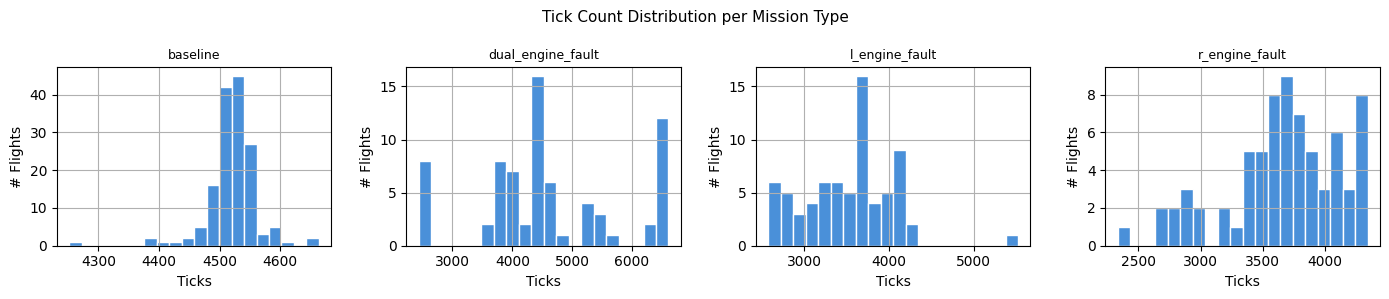


NOTE: dual_engine_fault has two tick populations — this is INTENTIONAL.
  Short flights (~2400–2600 ticks) = aircraft crashed fast (low altitude, 
  immediate ground impact after full thrust loss).
  Long flights (~6400–6600 ticks)  = aircraft spiraled through full 
  trajectory arc before crash.
  Both populations are valid severity morphology signal for RQ3.
  No truncation needed.



In [5]:
# ============================================================
# AUDIT 4 — TICKS PER FLIGHT
# Two populations in dual_engine_fault are INTENTIONAL
# short flights = fast crash (low alt), long = spiral crash
# ============================================================

print("=" * 60)
print("AUDIT 4 — TICKS PER FLIGHT")
print("=" * 60)

ticks = df.groupby(FLIGHT_COL).size().rename("tick_count")
flight_meta = df.groupby(FLIGHT_COL)[[MISSION_COL, BAND_COL]].first()
flight_info = ticks.to_frame().join(flight_meta)

print(f"  Min ticks  : {ticks.min()}")
print(f"  Max ticks  : {ticks.max()}")
print(f"  Mean ticks : {ticks.mean():.1f}")
print(f"  Std ticks  : {ticks.std():.1f}")

# Show distribution per mission type
print("\nTick count distribution per mission type:")
display(
    flight_info.groupby(MISSION_COL)["tick_count"]
    .agg(["min", "max", "mean", "std", "count"])
    .round(1)
)

# Plot
fig, axes = plt.subplots(1, len(df[MISSION_COL].unique()), figsize=(14, 3), sharey=False)
for ax, (mtype, grp) in zip(axes, flight_info.groupby(MISSION_COL)):
    grp["tick_count"].hist(bins=20, ax=ax, color="#4A90D9", edgecolor="white")
    ax.set_title(mtype, fontsize=9)
    ax.set_xlabel("Ticks")
    ax.set_ylabel("# Flights")
fig.suptitle("Tick Count Distribution per Mission Type", fontsize=11)
plt.tight_layout()
plt.show()

print("""
NOTE: dual_engine_fault has two tick populations — this is INTENTIONAL.
  Short flights (~2400–2600 ticks) = aircraft crashed fast (low altitude, 
  immediate ground impact after full thrust loss).
  Long flights (~6400–6600 ticks)  = aircraft spiraled through full 
  trajectory arc before crash.
  Both populations are valid severity morphology signal for RQ3.
  No truncation needed.
""")

In [6]:
# ============================================================
# AUDIT 5 — TIMESTAMP CONTINUITY (Gap Detection)
# ============================================================

print("=" * 60)
print("AUDIT 5 — TIMESTAMP GAP CHECK")
print("=" * 60)

EXPECTED_S   = 0.033    # ~30Hz
GAP_THRESH_S = 0.1      # flag gaps > 3 missed ticks

gap_summary = []

for fid, fdf in df.groupby(FLIGHT_COL):
    ts    = fdf.sort_values("timestamp")["timestamp"].values
    diffs = np.diff(ts)
    big   = diffs[diffs > GAP_THRESH_S]
    if len(big):
        gap_summary.append({
            "mission_id"  : fid,
            "n_gaps"      : len(big),
            "max_gap_s"   : round(big.max(), 3),
            "mission_type": fdf[MISSION_COL].iloc[0],
            "band"        : fdf[BAND_COL].iloc[0],
        })

if not gap_summary:
    print(f"✅ No timestamp gaps > {GAP_THRESH_S}s in any flight")
else:
    gap_df = pd.DataFrame(gap_summary).sort_values("max_gap_s", ascending=False)
    print(f"⚠️  {len(gap_df)} flights with gaps:\n")
    display(gap_df)

AUDIT 5 — TIMESTAMP GAP CHECK
⚠️  252 flights with gaps:



,mission_id,n_gaps,max_gap_s,mission_type,band
17,15e05fbd-3907-4395-9aa0-7276ed0242c4,20,0.575,dual_engine_fault,dual_engine_1000ft_450kts
173,b6e84cfb-8b68-4385-9d50-ee90bfdccac4,11,0.555,dual_engine_fault,dual_engine_1000ft_350kts
217,d9350240-879c-47db-87c5-11e6c3834468,20,0.496,baseline,baseline_8000ft_350kts
143,970e2ea1-a2ac-4a96-9fc0-72959931e150,6,0.485,baseline,baseline_1000ft_450kts
86,5d343021-cafd-46db-ac0f-c1b67db09eda,10,0.431,dual_engine_fault,dual_engine_20000ft_400kts
...,...,...,...,...,...
98,66f85a14-0c88-46af-9a49-80d89e68aa69,4,0.108,baseline,baseline_20000ft_450kts
27,1b9f6797-dfeb-4f2a-a0da-84ae9c61301d,1,0.105,baseline,baseline_20000ft_350kts
9,0f1a5b7f-2022-469c-aacc-b4b9fb8c0f6e,1,0.105,r_engine_fault,r_engine_20000ft_400kts
243,f336bdd2-ef2d-4231-b92e-2342f6fdf71e,1,0.103,baseline,baseline_1000ft_400kts


In [7]:
# ============================================================
# AUDIT 6 — SENSOR STATS + KNOWN ISSUES FLAGGED
# ============================================================

print("=" * 60)
print("AUDIT 6 — SENSOR STATS")
print("=" * 60)

sensor_cols = [c for c in df.columns if c.startswith("sensors_")]
display(df[sensor_cols].describe().round(3).T)

print("""
KNOWN ISSUES (confirmed from data — decisions made):

  sensors_alt_radar     → CAPPED at 1502m AGL (radar altimeter hardware limit)
                           50th and 75th percentile both = 1502.0
                           Decision: EXCLUDE from all models, use sensors_alt_baro

  sensors_roll          → IN RADIANS (range -π to +π)
  sensors_pitch         → IN RADIANS
  sensors_yaw           → IN RADIANS
                           Decision: CONVERT to degrees in Phase 2

  sensors_wind_x/y/z    → ALL ZERO (no wind configured in DCS)
  sensors_acs_active    → ALL ZERO throughout all flights
  sensors_eos_active    → ALL ZERO throughout all flights
                           Decision: DROP from feature set (zero variance)

  sensors_g_load        → Extreme values (min -51.94G, max 84.09G)
  sensors_yaw_rate      → Extreme values (±900 deg/s)
  sensors_roll_rate     → Extreme values (±428 deg/s)
  sensors_pitch_rate    → Extreme values (±986 deg/s)
                           These are INTENTIONAL crash-phase values
                           Decision: KEEP — they are valid RQ3 severity signal
""")

AUDIT 6 — SENSOR STATS


,count,mean,std,min,25%,50%,75%,max
sensors_aoa,1540913.0,3.679,1.593,-51.750,2.800,3.410,4.350,24.770
sensors_tas,1540913.0,221.204,30.868,33.240,202.240,223.590,241.720,319.440
sensors_vsi,1540913.0,-10.465,40.636,-297.170,-1.250,0.000,0.060,96.170
sensors_yaw,1540913.0,2.488,1.838,0.000,1.070,1.420,4.240,6.280
sensors_mach,1540913.0,0.667,0.085,0.400,0.607,0.675,0.733,0.934
sensors_roll,1540913.0,0.011,0.437,-3.140,0.000,0.000,0.000,3.120
sensors_pitch,1540913.0,0.017,0.190,-1.560,0.040,0.050,0.070,0.750
sensors_rpm_l,1540913.0,77.117,29.037,0.000,82.200,90.600,94.400,97.600
sensors_rpm_r,1540913.0,76.883,29.151,0.000,82.200,90.500,94.400,97.600
sensors_vel_x,1540913.0,43.679,126.153,-258.797,-47.802,64.327,117.172,260.124



KNOWN ISSUES (confirmed from data — decisions made):

  sensors_alt_radar     → CAPPED at 1502m AGL (radar altimeter hardware limit)
                           50th and 75th percentile both = 1502.0
                           Decision: EXCLUDE from all models, use sensors_alt_baro

  sensors_roll          → IN RADIANS (range -π to +π)
  sensors_pitch         → IN RADIANS
  sensors_yaw           → IN RADIANS
                           Decision: CONVERT to degrees in Phase 2

  sensors_wind_x/y/z    → ALL ZERO (no wind configured in DCS)
  sensors_acs_active    → ALL ZERO throughout all flights
  sensors_eos_active    → ALL ZERO throughout all flights
                           Decision: DROP from feature set (zero variance)

  sensors_g_load        → Extreme values (min -51.94G, max 84.09G)
  sensors_yaw_rate      → Extreme values (±900 deg/s)
  sensors_roll_rate     → Extreme values (±428 deg/s)
  sensors_pitch_rate    → Extreme values (±986 deg/s)
                           These are

In [8]:
# ============================================================
# AUDIT 7 — BINARY / FLAG CHANNEL INTEGRITY
# ============================================================

print("=" * 60)
print("AUDIT 7 — BINARY CHANNEL CHECK")
print("=" * 60)

binary_cols = [
    "sensors_fire_l", "sensors_fire_r",
    "sensors_hyd_fail", "sensors_master_warn",
    "sensors_acs_active", "sensors_eos_active"
]

for col in binary_cols:
    unique_vals = sorted(df[col].dropna().unique())
    bad         = [v for v in unique_vals if v not in (0, 0.0, 1, 1.0)]
    status      = "✅" if not bad else "⚠️ "
    print(f"  {status} {col:30s} unique values: {unique_vals}")

# Cross check: fire signals vs mission type
print("\nFlights with sensors_fire_l = 1 per mission type:")
display(
    df[df["sensors_fire_l"] == 1]
    .groupby(MISSION_COL)[FLIGHT_COL]
    .nunique()
    .rename("flights_with_fire_L")
    .to_frame()
)

print("\nFlights with sensors_fire_r = 1 per mission type:")
display(
    df[df["sensors_fire_r"] == 1]
    .groupby(MISSION_COL)[FLIGHT_COL]
    .nunique()
    .rename("flights_with_fire_R")
    .to_frame()
)

AUDIT 7 — BINARY CHANNEL CHECK
  ✅ sensors_fire_l                 unique values: [np.int64(0), np.int64(1)]
  ✅ sensors_fire_r                 unique values: [np.int64(0), np.int64(1)]
  ✅ sensors_hyd_fail               unique values: [np.int64(0), np.int64(1)]
  ✅ sensors_master_warn            unique values: [np.int64(0), np.int64(1)]
  ✅ sensors_acs_active             unique values: [np.int64(0)]
  ✅ sensors_eos_active             unique values: [np.int64(0)]

Flights with sensors_fire_l = 1 per mission type:


,flights_with_fire_L
flight_data_mission_type,
dual_engine_fault,72
l_engine_fault,72



Flights with sensors_fire_r = 1 per mission type:


,flights_with_fire_R
flight_data_mission_type,
dual_engine_fault,72
r_engine_fault,72


AUDIT 8 — MASTER_WARN ONSET TIMING
Master_warn onset timing per mission type (seconds from mission start):


,min,max,mean,std,count
mission_type,,,,,
dual_engine_fault,61.000,72.034,61.934,1.823,72
l_engine_fault,61.005,77.032,66.060,4.073,72
r_engine_fault,61.001,72.031,66.696,3.351,72


✅ All master_warn onsets within 60–90s window (±2s grace)
✅ All fault flights produced a master_warn signal


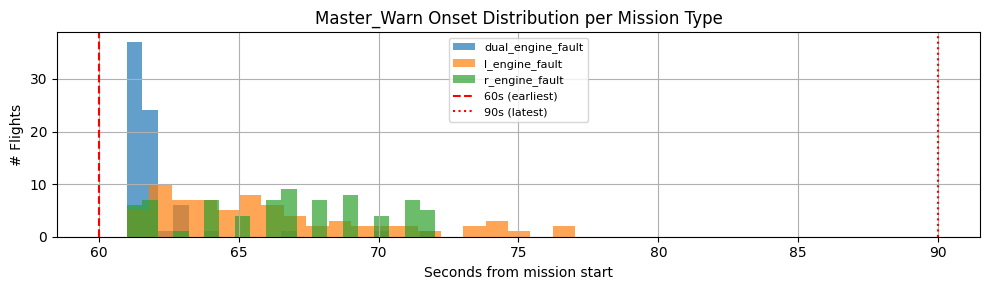

In [9]:
# ============================================================
# AUDIT 8 — MASTER_WARN ONSET TIMING
# Should fire between 60–90s (randomized window)
# ============================================================

print("=" * 60)
print("AUDIT 8 — MASTER_WARN ONSET TIMING")
print("=" * 60)

onset_records = []

for fid, fdf in df[df[MISSION_COL] != BASELINE].groupby(FLIGHT_COL):
    fdf_s     = fdf.sort_values("timestamp")
    warn_rows = fdf_s[fdf_s["sensors_master_warn"] == 1]
    onset_records.append({
        "mission_id"       : fid,
        "mission_type"     : fdf[MISSION_COL].iloc[0],
        "band"             : fdf[BAND_COL].iloc[0],
        "master_warn_onset": warn_rows["timestamp"].min() if len(warn_rows) else np.nan
    })

onset_df = pd.DataFrame(onset_records)

print("Master_warn onset timing per mission type (seconds from mission start):")
display(
    onset_df.groupby("mission_type")["master_warn_onset"]
    .agg(["min", "max", "mean", "std", "count"])
    .round(3)
)

# Flag anything outside 58–92s
outside = onset_df[
    (onset_df["master_warn_onset"] < 58) |
    (onset_df["master_warn_onset"] > 92)
]
if outside.empty:
    print("✅ All master_warn onsets within 60–90s window (±2s grace)")
else:
    print(f"⚠️  {len(outside)} flights outside expected window:")
    display(outside)

no_warn = onset_df[onset_df["master_warn_onset"].isna()]
if no_warn.empty:
    print("✅ All fault flights produced a master_warn signal")
else:
    print(f"⚠️  {len(no_warn)} fault flights with no master_warn:")
    display(no_warn)

# Plot
fig, ax = plt.subplots(figsize=(10, 3))
for mtype, grp in onset_df.dropna().groupby("mission_type"):
    grp["master_warn_onset"].hist(bins=20, ax=ax, alpha=0.7, label=mtype)
ax.axvline(60, color="red", linestyle="--", linewidth=1.5, label="60s (earliest)")
ax.axvline(90, color="red", linestyle=":",  linewidth=1.5, label="90s (latest)")
ax.set_title("Master_Warn Onset Distribution per Mission Type")
ax.set_xlabel("Seconds from mission start")
ax.set_ylabel("# Flights")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [10]:
# ============================================================
# PHASE 1 — SUMMARY
# ============================================================

print()
print("=" * 60)
print("PHASE 1 AUDIT — SUMMARY")
print("=" * 60)
print(f"  Rows              : {len(df):,}")
print(f"  Columns           : {df.shape[1]}")
print(f"  Unique flights    : {df[FLIGHT_COL].nunique()}")
print(f"  Mission types     : {sorted(df[MISSION_COL].unique())}")
print(f"  Band categories   : {sorted(df[BAND_COL].unique())}")
print(f"  Nulls             : 0 ✅")
print(f"  Timestamp gaps    : none ✅")
print()
print("  Issues to fix in Phase 2:")
print("  → Convert sensors_roll, sensors_pitch, sensors_yaw: radians → degrees")
print("  → Drop sensors_alt_radar, sensors_wind_x/y/z, sensors_acs_active, sensors_eos_active")
print("  → Derive time_rel_fault_s from master_warn rising edge per fault flight")
print()
print("  Data integrity: ✅ Ready for Phase 2")


PHASE 1 AUDIT — SUMMARY
  Rows              : 1,540,913
  Columns           : 38


  Unique flights    : 369
  Mission types     : ['baseline', 'dual_engine_fault', 'l_engine_fault', 'r_engine_fault']
  Band categories   : ['baseline_1000ft_350kts', 'baseline_1000ft_400kts', 'baseline_1000ft_450kts', 'baseline_20000ft_350kts', 'baseline_20000ft_400kts', 'baseline_20000ft_450kts', 'baseline_8000ft_350kts', 'baseline_8000ft_400kts', 'baseline_8000ft_450kts', 'dual_engine_1000ft_350kts', 'dual_engine_1000ft_400kts', 'dual_engine_1000ft_450kts', 'dual_engine_20000ft_350kts', 'dual_engine_20000ft_400kts', 'dual_engine_20000ft_450kts', 'dual_engine_8000ft_350kts', 'dual_engine_8000ft_400kts', 'dual_engine_8000ft_450kts', 'l_engine_1000ft_350kts', 'l_engine_1000ft_400kts', 'l_engine_1000ft_450kts', 'l_engine_20000ft_350kts', 'l_engine_20000ft_400kts', 'l_engine_20000ft_450kts', 'l_engine_8000ft_350kts', 'l_engine_8000ft_400kts', 'l_engine_8000ft_450kts', 'r_engine_1000ft_350kts', 'r_engine_1000ft_400kts', 'r_engine_1000ft_450kts', 'r_engine_20000ft_350kts', 'r_engine_20000f

## Phase 2: Temporal Reference Frame

In [19]:
df = df.sort_values([FLIGHT_COL, "timestamp"]).reset_index(drop=True)


In [20]:
print("✅ Sorted by mission_id → timestamp")
print(f"   Shape : {df.shape}")
print(f"\nFirst 5 rows:")
display(df[[FLIGHT_COL, MISSION_COL, "timestamp"]].head(5))
print(f"\nLast 5 rows:")
display(df[[FLIGHT_COL, MISSION_COL, "timestamp"]].tail(5))

✅ Sorted by mission_id → timestamp
   Shape : (1540913, 34)

First 5 rows:


,mission_id,flight_data_mission_type,timestamp
0,000febff-1ae2-4a89-9560-f67f4aad4e0a,r_engine_fault,0.025
1,000febff-1ae2-4a89-9560-f67f4aad4e0a,r_engine_fault,0.053
2,000febff-1ae2-4a89-9560-f67f4aad4e0a,r_engine_fault,0.081
3,000febff-1ae2-4a89-9560-f67f4aad4e0a,r_engine_fault,0.108
4,000febff-1ae2-4a89-9560-f67f4aad4e0a,r_engine_fault,0.137



Last 5 rows:


,mission_id,flight_data_mission_type,timestamp
1540908,ffc57431-7b0e-4c49-b53f-cd70dcd885bb,r_engine_fault,97.122
1540909,ffc57431-7b0e-4c49-b53f-cd70dcd885bb,r_engine_fault,97.155
1540910,ffc57431-7b0e-4c49-b53f-cd70dcd885bb,r_engine_fault,97.188
1540911,ffc57431-7b0e-4c49-b53f-cd70dcd885bb,r_engine_fault,97.222
1540912,ffc57431-7b0e-4c49-b53f-cd70dcd885bb,r_engine_fault,97.255


In [21]:
# ============================================================
# STEP 2 — DETECT FAULT ONSET PER FAULT FLIGHT
# T=0 = timestamp where sensors_master_warn flips 0 → 1
# ============================================================

onset_records = []

for fid, fdf in df.groupby(FLIGHT_COL):
    mission_type = fdf[MISSION_COL].iloc[0]
    fdf_sorted   = fdf.sort_values("timestamp")

    if mission_type == BASELINE:
        onset_records.append({
            "mission_id"   : fid,
            "mission_type" : mission_type,
            "band"         : fdf[BAND_COL].iloc[0],
            "fault_onset_s": np.nan,
            "onset_source" : "baseline"
        })

    else:
        warn  = fdf_sorted["sensors_master_warn"].values
        time  = fdf_sorted["timestamp"].values

        # Find first 0 → 1 rising edge
        edges = np.where((warn[:-1] == 0) & (warn[1:] == 1))[0]

        if len(edges) > 0:
            t0 = time[edges[0] + 1]
            onset_records.append({
                "mission_id"   : fid,
                "mission_type" : mission_type,
                "band"         : fdf[BAND_COL].iloc[0],
                "fault_onset_s": t0,
                "onset_source" : "master_warn_rising_edge"
            })
        else:
            onset_records.append({
                "mission_id"   : fid,
                "mission_type" : mission_type,
                "band"         : fdf[BAND_COL].iloc[0],
                "fault_onset_s": np.nan,
                "onset_source" : "NOT_FOUND"
            })

onset_df = pd.DataFrame(onset_records)

# ── Check for missing onsets ─────────────────────────────────
not_found = onset_df[
    (onset_df["mission_type"] != BASELINE) &
    (onset_df["onset_source"] == "NOT_FOUND")
]

if not_found.empty:
    print("✅ Fault onset detected in all fault flights")
else:
    print(f"⚠️  {len(not_found)} fault flights with no master_warn signal:")
    display(not_found)

# ── Onset timing summary ─────────────────────────────────────
print("\nFault onset timing per mission type:")
display(
    onset_df[onset_df["mission_type"] != BASELINE]
    .groupby("mission_type")["fault_onset_s"]
    .agg(["min", "max", "mean", "std", "count"])
    .round(3)
)

✅ Fault onset detected in all fault flights

Fault onset timing per mission type:


,min,max,mean,std,count
mission_type,,,,,
dual_engine_fault,61.000,72.034,61.934,1.823,72
l_engine_fault,61.005,77.032,66.060,4.073,72
r_engine_fault,61.001,72.031,66.696,3.351,72


Observed fault window : 61.000s – 77.032s
✅ All onsets within expected 60–90s window (±2s grace)


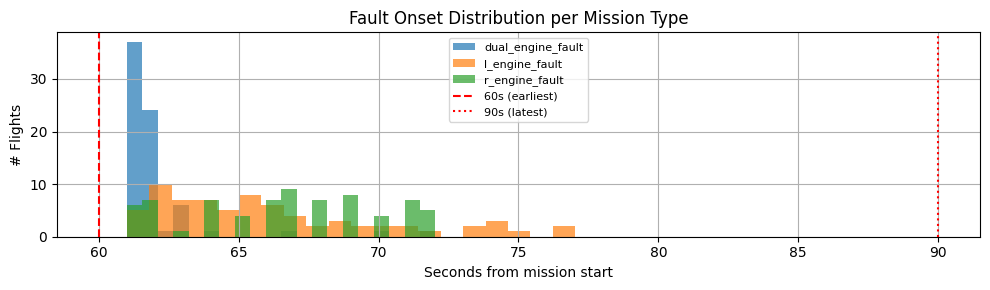

In [22]:
# ============================================================
# STEP 3 — VERIFY ONSET TIMING (should be 60–90s)
# ============================================================

fault_onsets = onset_df[onset_df["mission_type"] != BASELINE].dropna()

print(f"Observed fault window : {fault_onsets['fault_onset_s'].min():.3f}s – {fault_onsets['fault_onset_s'].max():.3f}s")

outside = fault_onsets[
    (fault_onsets["fault_onset_s"] < 58.0) |
    (fault_onsets["fault_onset_s"] > 92.0)
]

if outside.empty:
    print("✅ All onsets within expected 60–90s window (±2s grace)")
else:
    print(f"⚠️  {len(outside)} flights outside expected window:")
    display(outside)

# Plot
fig, ax = plt.subplots(figsize=(10, 3))
for mtype, grp in fault_onsets.groupby("mission_type"):
    grp["fault_onset_s"].hist(bins=20, ax=ax, alpha=0.7, label=mtype)
ax.axvline(60, color="red", linestyle="--", linewidth=1.5, label="60s (earliest)")
ax.axvline(90, color="red", linestyle=":",  linewidth=1.5, label="90s (latest)")
ax.set_title("Fault Onset Distribution per Mission Type")
ax.set_xlabel("Seconds from mission start")
ax.set_ylabel("# Flights")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [23]:
# ============================================================
# STEP 4 — MERGE ONSET + CREATE time_rel_fault_s
# ============================================================

df = df.merge(
    onset_df[[FLIGHT_COL, "fault_onset_s"]],
    on=FLIGHT_COL,
    how="left"
)

# negative = before fault, 0 = fault onset, positive = after fault
# NaN for all baseline rows
df["time_rel_fault_s"] = df["timestamp"] - df["fault_onset_s"]

print("✅ time_rel_fault_s created")
print(f"\n  Fault flights — min : {df[df[MISSION_COL] != BASELINE]['time_rel_fault_s'].min():.3f}s")
print(f"  Fault flights — max : {df[df[MISSION_COL] != BASELINE]['time_rel_fault_s'].max():.3f}s")
print(f"  Baseline rows (NaN) : {df[df[MISSION_COL] == BASELINE]['time_rel_fault_s'].isna().sum():,}")

# ── Sanity check: show rows around T=0 for one fault flight ──
sample_fid = onset_df[onset_df["mission_type"] == "l_engine_fault"]["mission_id"].iloc[0]
window = df[
    (df[FLIGHT_COL] == sample_fid) &
    (df["time_rel_fault_s"].between(-2, 2))
].sort_values("time_rel_fault_s")

print(f"\nSanity check — l_engine_fault around T=0:")
display(
    window[[
        "timestamp", "time_rel_fault_s","fault_onset_s",
        "sensors_master_warn", "sensors_fire_l",
        "sensors_temp_l", "sensors_rpm_l"
    ]].reset_index(drop=True)
)

KeyError: 'fault_onset_s'

In [ ]:
# ============================================================
# STEP 5 — RADIAN → DEGREE CONVERSION
# sensors_roll, sensors_pitch, sensors_yaw are in radians
# ============================================================

RAD_COLS = ["sensors_roll", "sensors_pitch", "sensors_yaw"]

for col in RAD_COLS:
    before = (df[col].min(), df[col].max())
    df[col] = np.degrees(df[col])
    after  = (df[col].min(), df[col].max())
    print(f"  {col:20s}: [{before[0]:.4f}, {before[1]:.4f}] rad  →  [{after[0]:.2f}, {after[1]:.2f}]°")

print("\n✅ Angular columns converted to degrees")

  sensors_roll        : [-3.1400, 3.1200] rad  →  [-179.91, 178.76]°
  sensors_pitch       : [-1.5600, 0.7500] rad  →  [-89.38, 42.97]°
  sensors_yaw         : [0.0000, 6.2800] rad  →  [0.00, 359.82]°

✅ Angular columns converted to degrees


In [ ]:
# ============================================================
# STEP 6 — DROP DEAD COLUMNS
# ============================================================

DROP_COLS = [
    "sensors_alt_radar",                          # capped at 1502m
    "sensors_wind_x", "sensors_wind_y",           # always zero
    "sensors_wind_z",                             # always zero
    "sensors_acs_active", "sensors_eos_active",   # always zero
]

df.drop(columns=DROP_COLS, inplace=True)

print(f"✅ Dropped: {DROP_COLS}")
print(f"   Remaining shape  : {df.shape}")
print(f"   Sensor features  : {len([c for c in df.columns if c.startswith('sensors_')])}")
print(f"   All columns      : {list(df.columns)}")

✅ Dropped: ['sensors_alt_radar', 'sensors_wind_x', 'sensors_wind_y', 'sensors_wind_z', 'sensors_acs_active', 'sensors_eos_active']
   Remaining shape  : (1540913, 34)
   Sensor features  : 26
   All columns      : ['id', 'mission_id', 'ingest_time', 'sensors_aoa', 'sensors_tas', 'sensors_vsi', 'sensors_yaw', 'sensors_mach', 'sensors_roll', 'sensors_pitch', 'sensors_rpm_l', 'sensors_rpm_r', 'sensors_vel_x', 'sensors_vel_y', 'sensors_vel_z', 'sensors_fire_l', 'sensors_fire_r', 'sensors_g_load', 'sensors_temp_l', 'sensors_temp_r', 'sensors_alt_baro', 'sensors_hyd_fail', 'sensors_yaw_rate', 'sensors_roll_rate', 'sensors_pitch_rate', 'sensors_fuel_flow_l', 'sensors_fuel_flow_r', 'sensors_master_warn', 'sensors_fuel_internal', 'timestamp', 'band_category', 'flight_data_mission_type', 'fault_onset_s', 'time_rel_fault_s']


In [ ]:
df.columns

Index(['id', 'mission_id', 'ingest_time', 'sensors_aoa', 'sensors_tas',
       'sensors_vsi', 'sensors_yaw', 'sensors_mach', 'sensors_roll',
       'sensors_pitch', 'sensors_rpm_l', 'sensors_rpm_r', 'sensors_vel_x',
       'sensors_vel_y', 'sensors_vel_z', 'sensors_fire_l', 'sensors_fire_r',
       'sensors_g_load', 'sensors_temp_l', 'sensors_temp_r',
       'sensors_alt_baro', 'sensors_hyd_fail', 'sensors_yaw_rate',
       'sensors_roll_rate', 'sensors_pitch_rate', 'sensors_fuel_flow_l',
       'sensors_fuel_flow_r', 'sensors_master_warn', 'sensors_fuel_internal',
       'timestamp', 'band_category', 'flight_data_mission_type',
       'fault_onset_s', 'time_rel_fault_s'],
      dtype='str')

## Feature Engineering

## Phase 3: Segmentation

In [24]:
FLIGHT_COL  = "mission_id"
MISSION_COL = "flight_data_mission_type"
BAND_COL    = "band_category"
BASELINE    = "baseline"

# ============================================================
# DOMAIN DEFINITIONS
# ============================================================

# RQ1 — all 27 sensor channels (fuel flow kept)
RQ1_CHANNELS = [
    # Thermal
    "sensors_temp_l", "sensors_temp_r",
    "sensors_fire_l", "sensors_fire_r",
    # Mechanical
    "sensors_rpm_l", "sensors_rpm_r",
    "sensors_hyd_fail",
    "sensors_fuel_flow_l", "sensors_fuel_flow_r",
    # Aerodynamic
    "sensors_aoa", "sensors_roll", "sensors_pitch",
    "sensors_tas", "sensors_alt_baro", "sensors_vsi",
    "sensors_mach", "sensors_g_load",
    # Motion
    "sensors_roll_rate", "sensors_pitch_rate", "sensors_yaw_rate",
    "sensors_yaw", "sensors_vel_x", "sensors_vel_y", "sensors_vel_z",
    # Other
    "sensors_master_warn",
    "sensors_rpm_l", "sensors_rpm_r",
]

# Deduplicate and clean
RQ1_CHANNELS = list(dict.fromkeys(RQ1_CHANNELS))
# Keep only columns that exist in df
RQ1_CHANNELS = [c for c in RQ1_CHANNELS if c in df.columns]



## RQ2

In [38]:
# RQ2 — 25 channels (fuel flow dropped)
RQ2_CHANNELS = [c for c in RQ1_CHANNELS
                if c not in ("sensors_fuel_flow_l", "sensors_fuel_flow_r")]
# Domain map for SHAP grouping (RQ1) and DAP (RQ2)
DOMAIN_MAP = {
    "Thermal"    : ["sensors_temp_l", "sensors_temp_r",
                    "sensors_fire_l", "sensors_fire_r"],
    "Mechanical" : ["sensors_rpm_l", "sensors_rpm_r",
                    "sensors_hyd_fail",
                    "sensors_fuel_flow_l", "sensors_fuel_flow_r"],
    "Aerodynamic": ["sensors_aoa", "sensors_roll", "sensors_pitch",
                    "sensors_tas", "sensors_alt_baro", "sensors_vsi",
                    "sensors_mach", "sensors_g_load"],
    "Motion"     : ["sensors_roll_rate", "sensors_pitch_rate",
                    "sensors_yaw_rate", "sensors_yaw",
                    "sensors_vel_x", "sensors_vel_y", "sensors_vel_z"],
}

# Label encoding
LABEL_MAP = {
    "baseline"        : 0,
    "l_engine_fault"  : 1,
    "r_engine_fault"  : 2,
    "dual_engine_fault": 3,
}

print(f"RQ1 channels : {len(RQ1_CHANNELS)}")
print(f"RQ2 channels : {len(RQ2_CHANNELS)}")
print(f"\nRQ1 channels: {RQ1_CHANNELS}")
print(f"\nRQ2 channels: {RQ2_CHANNELS}")

RQ1 channels : 25
RQ2 channels : 23

RQ1 channels: ['sensors_temp_l', 'sensors_temp_r', 'sensors_fire_l', 'sensors_fire_r', 'sensors_rpm_l', 'sensors_rpm_r', 'sensors_hyd_fail', 'sensors_fuel_flow_l', 'sensors_fuel_flow_r', 'sensors_aoa', 'sensors_roll', 'sensors_pitch', 'sensors_tas', 'sensors_alt_baro', 'sensors_vsi', 'sensors_mach', 'sensors_g_load', 'sensors_roll_rate', 'sensors_pitch_rate', 'sensors_yaw_rate', 'sensors_yaw', 'sensors_vel_x', 'sensors_vel_y', 'sensors_vel_z', 'sensors_master_warn']

RQ2 channels: ['sensors_temp_l', 'sensors_temp_r', 'sensors_fire_l', 'sensors_fire_r', 'sensors_rpm_l', 'sensors_rpm_r', 'sensors_hyd_fail', 'sensors_aoa', 'sensors_roll', 'sensors_pitch', 'sensors_tas', 'sensors_alt_baro', 'sensors_vsi', 'sensors_mach', 'sensors_g_load', 'sensors_roll_rate', 'sensors_pitch_rate', 'sensors_yaw_rate', 'sensors_yaw', 'sensors_vel_x', 'sensors_vel_y', 'sensors_vel_z', 'sensors_master_warn']


In [39]:
# ============================================================
# PHASE 3B — RQ2 SEGMENTATION
# Fixed window T=0 → T+15s per fault flight
# Output: 3D array [n_flights × time_steps × 25_channels]
# ============================================================

POST_FAULT_WINDOW_S = 15.0                           # seconds post fault
TICKS_PER_SEC       = 30                             # Hz
N_TIMESTEPS         = int(POST_FAULT_WINDOW_S * TICKS_PER_SEC)  # 450 ticks

# RQ2 label map (no baseline — RQ2 only classifies fault type)
RQ2_LABEL_MAP = {
    "l_engine_fault"   : 0,
    "r_engine_fault"   : 1,
    "dual_engine_fault": 2,
}

rq2_sequences = []
rq2_labels    = []
rq2_metadata  = []

fault_df = df[df[MISSION_COL] != BASELINE].copy()

for fid, fdf in fault_df.groupby(FLIGHT_COL):
    mission_type = fdf[MISSION_COL].iloc[0]
    band         = fdf[BAND_COL].iloc[0]

    # Get post-fault window only
    post_fault = fdf[
        (fdf["time_rel_fault_s"] >= 0) &
        (fdf["time_rel_fault_s"] <  POST_FAULT_WINDOW_S)
    ].sort_values("time_rel_fault_s")

    if len(post_fault) < 10:   # flight crashed immediately, skip
        print(f"  ⚠️  Skipping {fid} — only {len(post_fault)} post-fault ticks")
        continue

    # Extract channel values as numpy array
    seq = post_fault[RQ2_CHANNELS].values.astype(float)  # [actual_ticks × 25]

    # Pad or truncate to fixed N_TIMESTEPS
    if len(seq) >= N_TIMESTEPS:
        seq = seq[:N_TIMESTEPS]                           # truncate
    else:
        pad_len = N_TIMESTEPS - len(seq)
        pad     = np.zeros((pad_len, len(RQ2_CHANNELS)))
        seq     = np.vstack([seq, pad])                   # zero-pad at end

    rq2_sequences.append(seq)
    rq2_labels.append(RQ2_LABEL_MAP[mission_type])
    rq2_metadata.append({
        "mission_id"  : fid,
        "mission_type": mission_type,
        "band"        : band,
        "label"       : RQ2_LABEL_MAP[mission_type]
    })

# Stack into 3D array
X_rq2 = np.stack(rq2_sequences, axis=0)   # [n_flights × 450 × 25]
y_rq2 = np.array(rq2_labels)

print("=" * 60)
print("PHASE 3B — RQ2 DATASET BUILT")
print("=" * 60)
print(f"  X shape         : {X_rq2.shape}  [flights × timesteps × channels]")
print(f"  y shape         : {y_rq2.shape}")
print(f"  Timesteps       : {N_TIMESTEPS} ({POST_FAULT_WINDOW_S}s at {TICKS_PER_SEC}Hz)")
print(f"  Channels        : {len(RQ2_CHANNELS)}")
print(f"\nLabel distribution:")
unique, counts = np.unique(y_rq2, return_counts=True)
rq2_label_names = {0:"l_engine_fault", 1:"r_engine_fault", 2:"dual_engine_fault"}
for lbl, cnt in zip(unique, counts):
    print(f"  {rq2_label_names[lbl]:20s} (label={lbl}): {cnt} flights")

PHASE 3B — RQ2 DATASET BUILT
  X shape         : (216, 450, 23)  [flights × timesteps × channels]
  y shape         : (216,)
  Timesteps       : 450 (15.0s at 30Hz)
  Channels        : 23

Label distribution:
  l_engine_fault       (label=0): 72 flights
  r_engine_fault       (label=1): 72 flights
  dual_engine_fault    (label=2): 72 flights


PHASE 3B — SEQUENCE VERIFICATION PLOTS


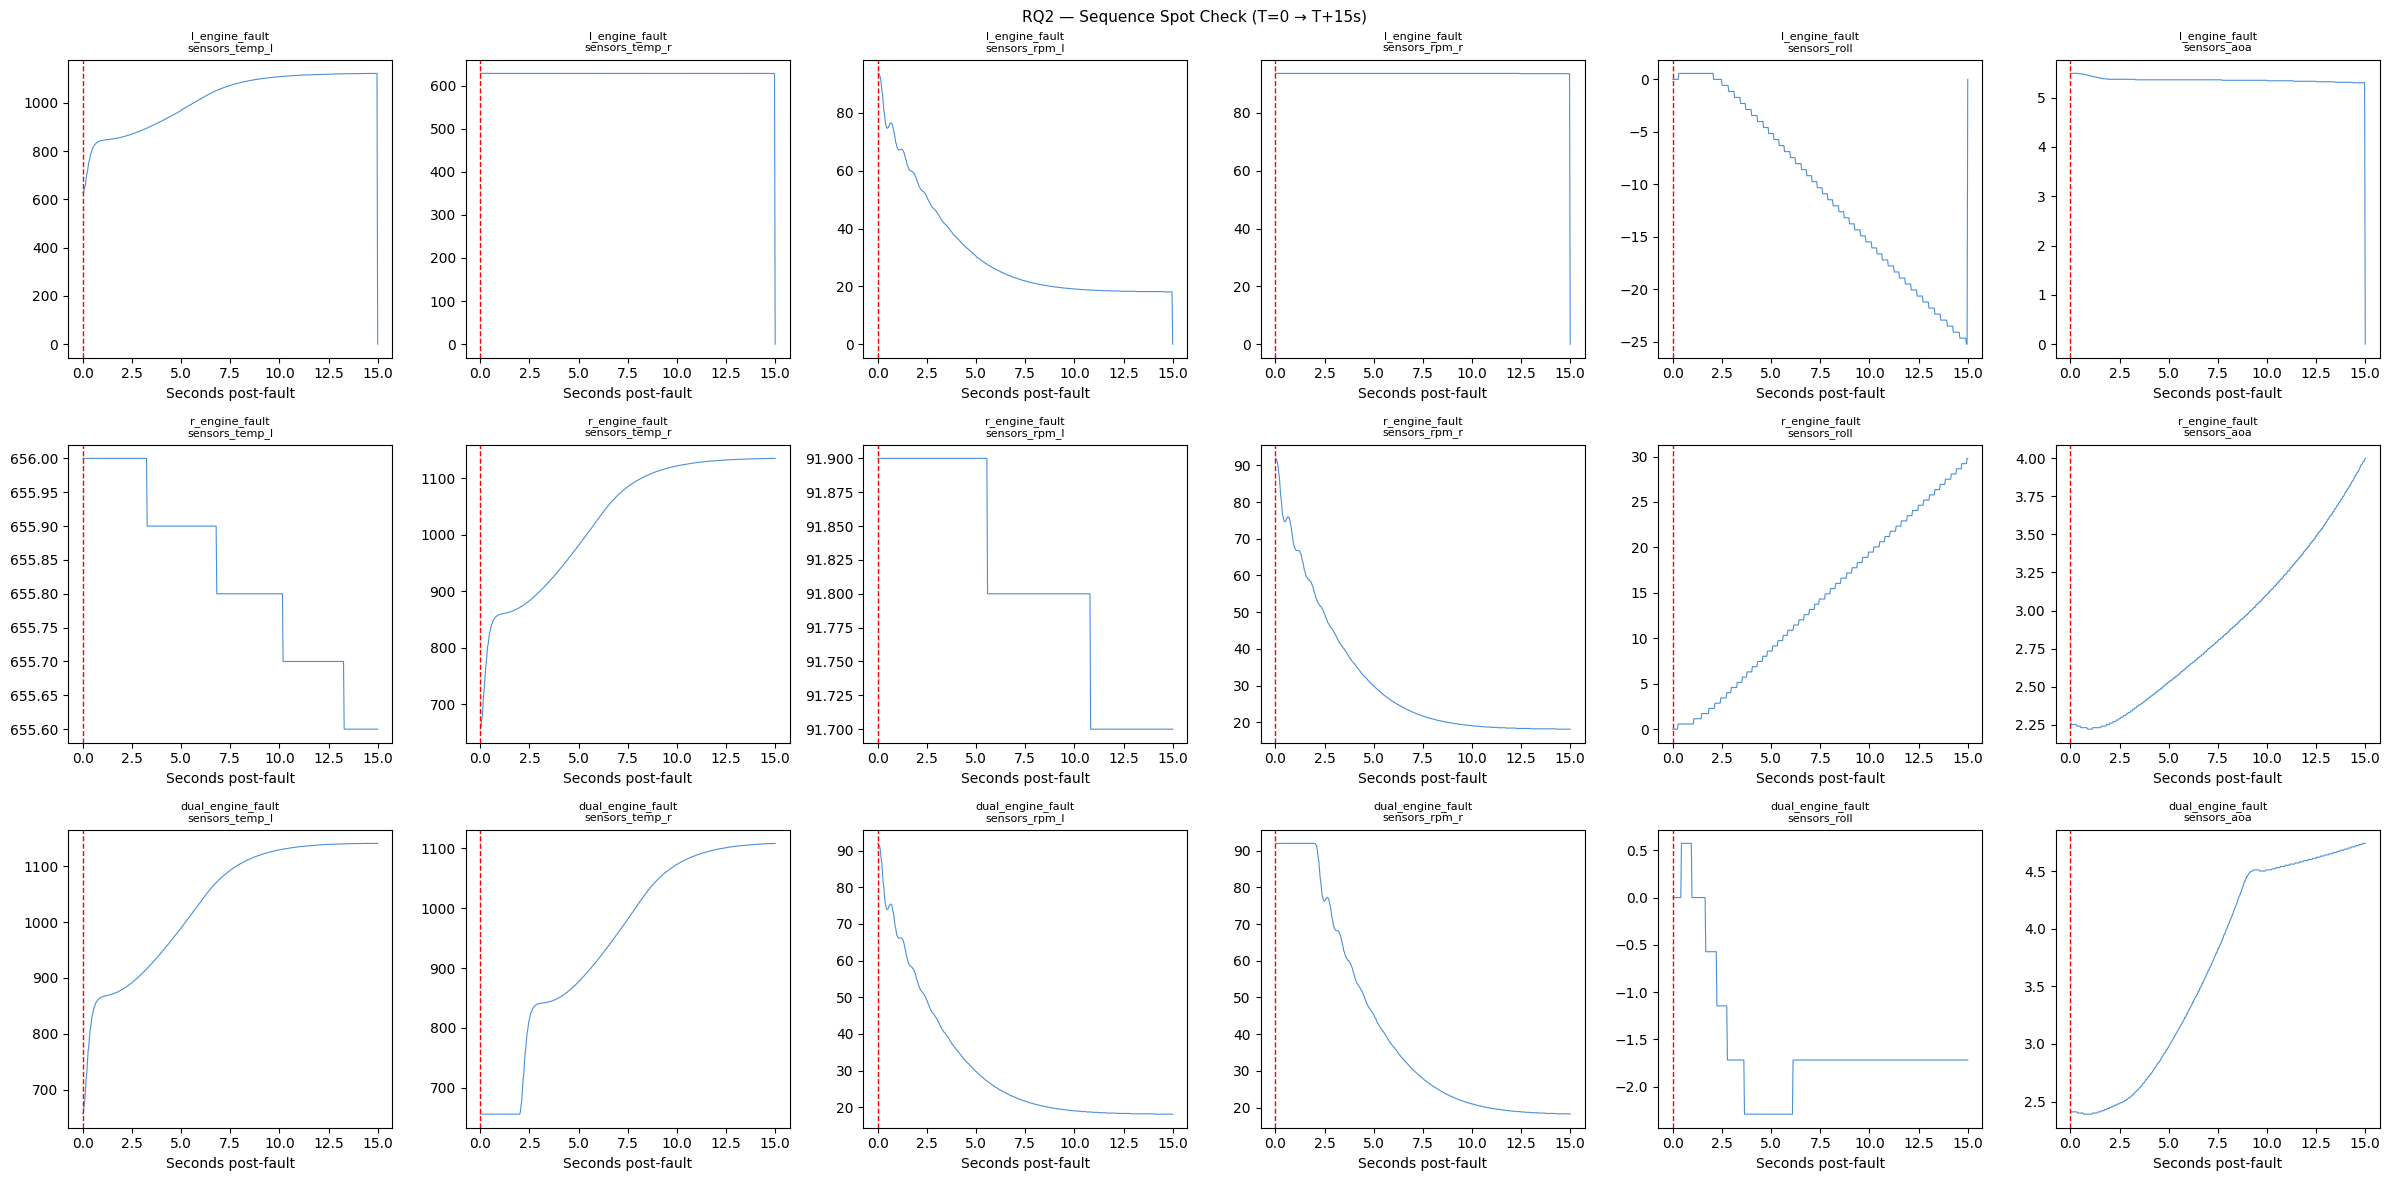

In [40]:
# ============================================================
# PHASE 3B — VERIFY SEQUENCES LOOK CORRECT
# Plot one flight per fault type — key channels around T=0
# ============================================================

print("=" * 60)
print("PHASE 3B — SEQUENCE VERIFICATION PLOTS")
print("=" * 60)

meta_df = pd.DataFrame(rq2_metadata)
time_axis = np.linspace(0, POST_FAULT_WINDOW_S, N_TIMESTEPS)

# Channels to spot-check
CHECK_CHANNELS = [
    "sensors_temp_l", "sensors_temp_r",
    "sensors_rpm_l",  "sensors_rpm_r",
    "sensors_roll",   "sensors_aoa"
]
check_idx = [RQ2_CHANNELS.index(c) for c in CHECK_CHANNELS if c in RQ2_CHANNELS]

fault_types  = list(RQ2_LABEL_MAP.keys())
n_check      = len(check_idx)
fig, axes    = plt.subplots(len(fault_types), n_check,
                             figsize=(4 * n_check, 4 * len(fault_types)))

for i, ftype in enumerate(fault_types):
    lbl       = RQ2_LABEL_MAP[ftype]
    flight_idx = np.where(y_rq2 == lbl)[0][0]   # first flight of this type
    seq        = X_rq2[flight_idx]               # [450 × 25]

    for j, (cidx, cname) in enumerate(zip(check_idx, CHECK_CHANNELS)):
        ax = axes[i][j]
        ax.plot(time_axis, seq[:, cidx], color="#4A90D9", linewidth=0.8)
        ax.axvline(0, color="red", linestyle="--", linewidth=1, label="T=0")
        ax.set_title(f"{ftype}\n{cname}", fontsize=8)
        ax.set_xlabel("Seconds post-fault")

fig.suptitle("RQ2 — Sequence Spot Check (T=0 → T+15s)", fontsize=11)
plt.tight_layout()
plt.show()

In [41]:
# ============================================================
# PHASE 3B — SAVE RQ2 DATASET
# ============================================================

RQ2_PATH = r"C:\MY_Files\DE\dcs_data_pipeline\Medallion\Silver Layer\rq2_sequences_1.npz"

np.savez(
    RQ2_PATH,
    X          = X_rq2,
    y          = y_rq2,
    channels   = np.array(RQ2_CHANNELS),
    label_names= np.array(["l_engine_fault", "r_engine_fault", "dual_engine_fault"])
)

# Save metadata separately as parquet for easy querying
RQ2_META_PATH = r"C:\MY_Files\DE\dcs_data_pipeline\Medallion\Silver Layer\rq2_metadata_1.parquet"
meta_df.to_parquet(RQ2_META_PATH, index=False)

print(f"✅ RQ2 sequences saved → {RQ2_PATH}")
print(f"✅ RQ2 metadata saved  → {RQ2_META_PATH}")
print(f"   X shape : {X_rq2.shape}")
print(f"   y shape : {y_rq2.shape}")

✅ RQ2 sequences saved → C:\MY_Files\DE\dcs_data_pipeline\Medallion\Silver Layer\rq2_sequences_1.npz
✅ RQ2 metadata saved  → C:\MY_Files\DE\dcs_data_pipeline\Medallion\Silver Layer\rq2_metadata_1.parquet
   X shape : (216, 450, 23)
   y shape : (216,)


In [42]:
# ============================================================
# PHASE 3 — FINAL SUMMARY
# ============================================================

print()
print("=" * 60)
print("PHASE 3 COMPLETE")
print("=" * 60)
print(f"""
  RQ1 Dataset (XGBoost input):
    File    : rq1_features.parquet
    Shape   : {rq1_df.shape}
    Windows : {len(rq1_df):,}
    Features: {len([c for c in rq1_df.columns if '__' in c])} 
              ({len(RQ1_CHANNELS)} channels × 5 stats)
    Labels  : 0=normal, 1=l_engine, 2=r_engine, 3=dual

  RQ2 Dataset (Transformer input):
    File    : rq2_sequences.npz
    X shape : {X_rq2.shape}  [flights × timesteps × channels]
    y shape : {y_rq2.shape}
    Window  : T=0 → T+{POST_FAULT_WINDOW_S}s post fault
    Labels  : 0=l_engine, 1=r_engine, 2=dual

  Domain map saved for SHAP grouping and DAP visualization.

  Ready for Phase 4 — Model Training
""")


PHASE 3 COMPLETE


NameError: name 'rq1_df' is not defined

In [ ]:
print(f"Expected 25, got: {len(RQ2_CHANNELS)}")
print(f"RQ2 channels: {RQ2_CHANNELS}")

# Find which channels are missing
expected = [
    "sensors_temp_l", "sensors_temp_r", "sensors_fire_l", "sensors_fire_r",
    "sensors_rpm_l", "sensors_rpm_r", "sensors_hyd_fail",
    "sensors_aoa", "sensors_roll", "sensors_pitch",
    "sensors_tas", "sensors_alt_baro", "sensors_vsi",
    "sensors_mach", "sensors_g_load",
    "sensors_roll_rate", "sensors_pitch_rate", "sensors_yaw_rate",
    "sensors_yaw", "sensors_vel_x", "sensors_vel_y", "sensors_vel_z",
    "sensors_master_warn", "sensors_pitch", "sensors_yaw"
]
missing = [c for c in expected if c not in RQ2_CHANNELS]
print(f"Missing: {missing}")

Expected 25, got: 23
RQ2 channels: ['sensors_temp_l', 'sensors_temp_r', 'sensors_fire_l', 'sensors_fire_r', 'sensors_rpm_l', 'sensors_rpm_r', 'sensors_hyd_fail', 'sensors_aoa', 'sensors_roll', 'sensors_pitch', 'sensors_tas', 'sensors_alt_baro', 'sensors_vsi', 'sensors_mach', 'sensors_g_load', 'sensors_roll_rate', 'sensors_pitch_rate', 'sensors_yaw_rate', 'sensors_yaw', 'sensors_vel_x', 'sensors_vel_y', 'sensors_vel_z', 'sensors_master_warn']
Missing: []


In [ ]:
print(pd.DataFrame(rq2_metadata)["mission_type"].value_counts())

mission_type
r_engine_fault       72
l_engine_fault       72
dual_engine_fault    72
Name: count, dtype: int64


## RQ1

In [25]:
# ============================================================
# PHASE 3A REVISED — COMPREHENSIVE FEATURE ENGINEERING
# ============================================================


WINDOW_S = 5.0
STRIDE_S = 2.5

LABEL_MAP = {
    "baseline"         : 0,
    "l_engine_fault"   : 1,
    "r_engine_fault"   : 2,
    "dual_engine_fault": 3,
}

RQ1_CHANNELS = [
    "sensors_temp_l", "sensors_temp_r",
    "sensors_fire_l", "sensors_fire_r",
    "sensors_rpm_l", "sensors_rpm_r",
    "sensors_hyd_fail",
    "sensors_fuel_flow_l", "sensors_fuel_flow_r",
    "sensors_aoa", "sensors_roll", "sensors_pitch",
    "sensors_tas", "sensors_alt_baro", "sensors_vsi",
    "sensors_mach", "sensors_g_load",
    "sensors_roll_rate", "sensors_pitch_rate", "sensors_yaw_rate",
    "sensors_yaw", "sensors_vel_x", "sensors_vel_y", "sensors_vel_z",
    "sensors_master_warn",
]
RQ1_CHANNELS = [c for c in RQ1_CHANNELS if c in df.columns]

In [26]:
# ============================================================
# FEATURE EXTRACTION FUNCTIONS
# ============================================================

def safe_slope(values):
    """Linear slope of signal. Returns 0 if < 2 points."""
    if len(values) < 2:
        return 0.0
    x = np.arange(len(values))
    return np.polyfit(x, values, 1)[0]

def safe_skew(values):
    if len(values) < 3:
        return 0.0
    try:
        return float(skew(values))
    except:
        return 0.0

def safe_kurtosis(values):
    if len(values) < 4:
        return 0.0
    try:
        return float(kurtosis(values))
    except:
        return 0.0

def extract_channel_features(vals, col_name):
    """
    Extract all per-channel features from a 1D signal array.
    Returns dict of {feature_name: value}
    """
    feats  = {}
    n      = len(vals)
    prefix = col_name

    if n == 0:
        return feats

    # ── 1. Basic statistics ──────────────────────────────────
    feats[f"{prefix}__mean"]    = np.mean(vals)
    feats[f"{prefix}__std"]     = np.std(vals)
    feats[f"{prefix}__min"]     = np.min(vals)
    feats[f"{prefix}__max"]     = np.max(vals)
    feats[f"{prefix}__median"]  = np.median(vals)
    feats[f"{prefix}__range"]   = np.max(vals) - np.min(vals)
    feats[f"{prefix}__p25"]     = np.percentile(vals, 25)
    feats[f"{prefix}__p75"]     = np.percentile(vals, 75)
    feats[f"{prefix}__iqr"]     = np.percentile(vals, 75) - np.percentile(vals, 25)

    # Coefficient of variation (std / mean) — relative variability
    mean_val = feats[f"{prefix}__mean"]
    feats[f"{prefix}__cv"] = (
        feats[f"{prefix}__std"] / abs(mean_val)
        if abs(mean_val) > 1e-9 else 0.0
    )

    # ── 2. Shape statistics ──────────────────────────────────
    feats[f"{prefix}__skew"]     = safe_skew(vals)
    feats[f"{prefix}__kurtosis"] = safe_kurtosis(vals)

    # ── 3. Dynamic / trend features ─────────────────────────
    feats[f"{prefix}__slope"] = safe_slope(vals)

    if n >= 2:
        d1 = np.diff(vals)                              # first derivative
        feats[f"{prefix}__d1_mean"] = np.mean(d1)
        feats[f"{prefix}__d1_std"]  = np.std(d1)
        feats[f"{prefix}__d1_max"]  = np.max(np.abs(d1))  # max rate of change
    else:
        feats[f"{prefix}__d1_mean"] = 0.0
        feats[f"{prefix}__d1_std"]  = 0.0
        feats[f"{prefix}__d1_max"]  = 0.0

    if n >= 3:
        d2 = np.diff(vals, n=2)                         # second derivative
        feats[f"{prefix}__d2_mean"] = np.mean(d2)
        feats[f"{prefix}__d2_std"]  = np.std(d2)
    else:
        feats[f"{prefix}__d2_mean"] = 0.0
        feats[f"{prefix}__d2_std"]  = 0.0

    # ── 4. Energy features ───────────────────────────────────
    feats[f"{prefix}__rms"]    = np.sqrt(np.mean(vals ** 2))
    feats[f"{prefix}__energy"] = np.sum(vals ** 2)
    feats[f"{prefix}__mad"]    = np.mean(np.abs(vals - np.mean(vals)))

    # ── 5. Crossing features ─────────────────────────────────
    # Zero crossing rate
    if n >= 2:
        zero_crossings = np.sum(np.diff(np.sign(vals)) != 0)
        feats[f"{prefix}__zcr"] = zero_crossings / n
    else:
        feats[f"{prefix}__zcr"] = 0.0

    # Mean crossing rate (how often signal crosses its own mean)
    if n >= 2:
        centered = vals - np.mean(vals)
        mean_crossings = np.sum(np.diff(np.sign(centered)) != 0)
        feats[f"{prefix}__mcr"] = mean_crossings / n
    else:
        feats[f"{prefix}__mcr"] = 0.0

    # ── 6. Extrema features ──────────────────────────────────
    if n >= 3:
        peaks,  _ = find_peaks(vals)
        troughs,_ = find_peaks(-vals)
        feats[f"{prefix}__n_peaks"]   = len(peaks)
        feats[f"{prefix}__n_troughs"] = len(troughs)
        # Peak prominence (how far peaks rise above surroundings)
        feats[f"{prefix}__peak_mean"] = (
            float(np.mean(vals[peaks])) if len(peaks) > 0 else float(np.mean(vals))
        )
    else:
        feats[f"{prefix}__n_peaks"]   = 0
        feats[f"{prefix}__n_troughs"] = 0
        feats[f"{prefix}__peak_mean"] = float(np.mean(vals))

    # ── 7. Autocorrelation at lag 1 ──────────────────────────
    if n >= 3:
        try:
            ac = np.corrcoef(vals[:-1], vals[1:])[0, 1]
            feats[f"{prefix}__autocorr_lag1"] = ac if not np.isnan(ac) else 0.0
        except:
            feats[f"{prefix}__autocorr_lag1"] = 0.0
    else:
        feats[f"{prefix}__autocorr_lag1"] = 0.0

    # ── 8. Start / end values (capture onset behavior) ───────
    feats[f"{prefix}__first"] = vals[0]
    feats[f"{prefix}__last"]  = vals[-1]
    feats[f"{prefix}__delta"] = vals[-1] - vals[0]   # total change across window

    return feats


def extract_cross_channel_features(window_df):
    """
    Cross-channel features — physically meaningful combinations.
    These are the most powerful for distinguishing L vs R vs Dual fault.
    """
    feats = {}

    def get(col):
        return window_df[col].values.astype(float) if col in window_df.columns else None

    rpm_l  = get("sensors_rpm_l")
    rpm_r  = get("sensors_rpm_r")
    temp_l = get("sensors_temp_l")
    temp_r = get("sensors_temp_r")
    fire_l = get("sensors_fire_l")
    fire_r = get("sensors_fire_r")
    ff_l   = get("sensors_fuel_flow_l")
    ff_r   = get("sensors_fuel_flow_r")
    roll   = get("sensors_roll")
    aoa    = get("sensors_aoa")
    tas    = get("sensors_tas")
    alt    = get("sensors_alt_baro")

    # ── RPM asymmetry (key discriminator L vs R) ─────────────
    if rpm_l is not None and rpm_r is not None:
        asym = rpm_l - rpm_r
        feats["cross__rpm_asymmetry_mean"]  = np.mean(asym)
        feats["cross__rpm_asymmetry_std"]   = np.std(asym)
        feats["cross__rpm_asymmetry_max"]   = np.max(np.abs(asym))
        feats["cross__rpm_asymmetry_slope"] = safe_slope(asym)
        feats["cross__rpm_total_mean"]      = np.mean(rpm_l + rpm_r)
        feats["cross__rpm_total_drop"]      = (rpm_l + rpm_r)[0] - (rpm_l + rpm_r)[-1]
        feats["cross__rpm_l_slope"]         = safe_slope(rpm_l)
        feats["cross__rpm_r_slope"]         = safe_slope(rpm_r)

    # ── Temperature asymmetry (key discriminator L vs R) ─────
    if temp_l is not None and temp_r is not None:
        temp_asym = temp_l - temp_r
        feats["cross__temp_asymmetry_mean"]  = np.mean(temp_asym)
        feats["cross__temp_asymmetry_std"]   = np.std(temp_asym)
        feats["cross__temp_asymmetry_max"]   = np.max(np.abs(temp_asym))
        feats["cross__temp_asymmetry_slope"] = safe_slope(temp_asym)
        feats["cross__temp_l_rise_rate"]     = safe_slope(temp_l)
        feats["cross__temp_r_rise_rate"]     = safe_slope(temp_r)
        feats["cross__temp_total_mean"]      = np.mean(temp_l + temp_r)
        feats["cross__temp_total_rise"]      = (temp_l + temp_r)[-1] - (temp_l + temp_r)[0]

    # ── Fire flag features ───────────────────────────────────
    if fire_l is not None and fire_r is not None:
        feats["cross__fire_l_active"]    = float(np.any(fire_l > 0))
        feats["cross__fire_r_active"]    = float(np.any(fire_r > 0))
        feats["cross__fire_both_active"] = float(np.any(fire_l > 0) and np.any(fire_r > 0))
        feats["cross__fire_asymmetry"]   = float(np.mean(fire_l) - np.mean(fire_r))
        feats["cross__fire_any_mean"]    = float(np.mean(np.maximum(fire_l, fire_r)))

    # ── Fuel flow asymmetry ──────────────────────────────────
    if ff_l is not None and ff_r is not None:
        ff_asym = ff_l - ff_r
        feats["cross__ff_asymmetry_mean"] = np.mean(ff_asym)
        feats["cross__ff_asymmetry_max"]  = np.max(np.abs(ff_asym))
        feats["cross__ff_total_mean"]     = np.mean(ff_l + ff_r)
        feats["cross__ff_total_slope"]    = safe_slope(ff_l + ff_r)

    # ── Aerodynamic response features ───────────────────────
    if roll is not None:
        feats["cross__roll_direction"]    = np.mean(roll)          # + = right, - = left
        feats["cross__roll_magnitude"]    = np.mean(np.abs(roll))
        feats["cross__roll_slope"]        = safe_slope(roll)
        feats["cross__roll_max_abs"]      = np.max(np.abs(roll))

    if aoa is not None:
        feats["cross__aoa_mean"]  = np.mean(aoa)
        feats["cross__aoa_slope"] = safe_slope(aoa)
        feats["cross__aoa_max"]   = np.max(aoa)

    if tas is not None:
        feats["cross__tas_slope"] = safe_slope(tas)   # airspeed change rate
        feats["cross__tas_delta"] = tas[-1] - tas[0]

    if alt is not None:
        feats["cross__alt_slope"] = safe_slope(alt)   # descent rate
        feats["cross__alt_delta"] = alt[-1] - alt[0]

    # ── RPM × Temperature interaction ───────────────────────
    # RPM drops while temp rises = classic engine fire pattern
    if rpm_l is not None and temp_l is not None:
        feats["cross__rpm_l_drop_x_temp_l_rise"] = (
            -safe_slope(rpm_l) * safe_slope(temp_l)
        )  # positive = RPM dropping AND temp rising simultaneously
    if rpm_r is not None and temp_r is not None:
        feats["cross__rpm_r_drop_x_temp_r_rise"] = (
            -safe_slope(rpm_r) * safe_slope(temp_r)
        )

    # ── Roll × RPM asymmetry interaction ────────────────────
    # Roll direction should match which engine failed
    if roll is not None and rpm_l is not None and rpm_r is not None:
        rpm_asym_mean = np.mean(rpm_l - rpm_r)
        roll_mean     = np.mean(roll)
        # If L fails: rpm_asym negative, roll negative (rolls left)
        # If R fails: rpm_asym positive, roll positive (rolls right)
        feats["cross__roll_rpm_alignment"] = roll_mean * rpm_asym_mean

    return feats

In [27]:
# ============================================================
# MAIN EXTRACTION LOOP — SLIDING WINDOWS
# ============================================================

rq1_rows = []
total_flights = df[FLIGHT_COL].nunique()

for i, (fid, fdf) in enumerate(df.groupby(FLIGHT_COL)):
    if i % 20 == 0:
        print(f"  Processing flight {i+1}/{total_flights}...")

    mission_type = fdf[MISSION_COL].iloc[0]
    band         = fdf[BAND_COL].iloc[0]
    fdf_sorted   = fdf.sort_values("timestamp").reset_index(drop=True)

    ts_start = fdf_sorted["timestamp"].iloc[0]
    ts_end   = fdf_sorted["timestamp"].iloc[-1]

    t = ts_start
    while t + WINDOW_S <= ts_end:
        w_start = t
        w_end   = t + WINDOW_S

        window = fdf_sorted[
            (fdf_sorted["timestamp"] >= w_start) &
            (fdf_sorted["timestamp"] <  w_end)
        ]

        if len(window) < 10:
            t += STRIDE_S
            continue

        # ── Label ────────────────────────────────────────────
        if mission_type == BASELINE:
            label = 0
        else:
            has_post_fault = (window["time_rel_fault_s"] >= 0).any()
            label = LABEL_MAP[mission_type] if has_post_fault else 0

        # ── Per-channel features ─────────────────────────────
        all_feats = {}
        for col in RQ1_CHANNELS:
            vals = window[col].values.astype(float)
            all_feats.update(extract_channel_features(vals, col))

        # ── Cross-channel features ───────────────────────────
        all_feats.update(extract_cross_channel_features(window))

        # ── Metadata ─────────────────────────────────────────
        all_feats["mission_id"]   = fid
        all_feats["mission_type"] = mission_type
        all_feats["band"]         = band
        all_feats["label"]        = label
        all_feats["w_start"]      = w_start
        all_feats["w_end"]        = w_end

        rq1_rows.append(all_feats)
        t += STRIDE_S

rq1_df = pd.DataFrame(rq1_rows)

feature_cols = [c for c in rq1_df.columns
                if c not in ("mission_id", "mission_type", "band",
                             "label", "w_start", "w_end")]

print(f"\n✅ RQ1 feature extraction complete")
print(f"   Total windows    : {len(rq1_df):,}")
print(f"   Total features   : {len(feature_cols)}")
print(f"   Per-channel feats: {len([c for c in feature_cols if '__' in c and not c.startswith('cross')])}")
print(f"   Cross-channel    : {len([c for c in feature_cols if c.startswith('cross')])}")

  Processing flight 1/369...


c:\Users\jagad\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\jagad\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


  Processing flight 21/369...
  Processing flight 41/369...
  Processing flight 61/369...
  Processing flight 81/369...
  Processing flight 101/369...
  Processing flight 121/369...
  Processing flight 141/369...
  Processing flight 161/369...
  Processing flight 181/369...
  Processing flight 201/369...
  Processing flight 221/369...
  Processing flight 241/369...
  Processing flight 261/369...
  Processing flight 281/369...
  Processing flight 301/369...
  Processing flight 321/369...
  Processing flight 341/369...
  Processing flight 361/369...

✅ RQ1 feature extraction complete
   Total windows    : 20,131
   Total features   : 789
   Per-channel feats: 750
   Cross-channel    : 39


In [32]:
# ============================================================
# FEATURE SUMMARY — What did we build?
# ============================================================

print("=" * 60)
print("FEATURE ENGINEERING SUMMARY")
print("=" * 60)

per_ch = [c for c in feature_cols if not c.startswith("cross")]
cross  = [c for c in feature_cols if c.startswith("cross")]

# Per-channel stats breakdown
stat_types = ["mean", "std", "min", "max", "median", "range",
              "p25", "p75", "iqr", "cv", "skew", "kurtosis",
              "slope", "d1_mean", "d1_std", "d1_max",
              "d2_mean", "d2_std", "rms", "energy", "mad",
              "zcr", "mcr", "n_peaks", "n_troughs", "peak_mean",
              "autocorr_lag1", "first", "last", "delta"]

print(f"\nPer-channel features ({len(stat_types)} stats × {len(RQ1_CHANNELS)} channels):")
for s in stat_types:
    count = len([c for c in per_ch if c.endswith(f"__{s}")])
    print(f"  {s:20s}: {count} features")

print(f"\nCross-channel features: {len(cross)}")
for c in cross:
    print(f"  {c}")

print(f"\n{'─'*40}")
print(f"  TOTAL FEATURES: {len(feature_cols)}")

# Label distribution
print(f"\nLabel distribution:")
label_names = {0:"normal", 1:"l_engine_fault",
               2:"r_engine_fault", 3:"dual_engine_fault"}
counts = rq1_df["label"].value_counts().sort_index()
for lbl, cnt in counts.items():
    print(f"  {label_names[lbl]:20s}: {cnt:,} ({cnt/len(rq1_df)*100:.1f}%)")

FEATURE ENGINEERING SUMMARY

Per-channel features (30 stats × 25 channels):
  mean                : 25 features
  std                 : 25 features
  min                 : 25 features
  max                 : 25 features
  median              : 25 features
  range               : 25 features
  p25                 : 25 features
  p75                 : 25 features
  iqr                 : 25 features
  cv                  : 25 features
  skew                : 25 features
  kurtosis            : 25 features
  slope               : 25 features
  d1_mean             : 25 features
  d1_std              : 25 features
  d1_max              : 25 features
  d2_mean             : 25 features
  d2_std              : 25 features
  rms                 : 25 features
  energy              : 25 features
  mad                 : 25 features
  zcr                 : 25 features
  mcr                 : 25 features
  n_peaks             : 25 features
  n_troughs           : 25 features
  peak_mean           : 

In [33]:
# ============================================================
# NaN / INF CHECK — Feature quality gate
# ============================================================

print("=" * 60)
print("FEATURE QUALITY CHECK")
print("=" * 60)

nan_counts = rq1_df[feature_cols].isna().sum()
inf_counts = rq1_df[feature_cols].isin([np.inf, -np.inf]).sum()

bad_nan = nan_counts[nan_counts > 0]
bad_inf = inf_counts[inf_counts > 0]

if bad_nan.empty:
    print("✅ No NaN values in any feature")
else:
    print(f"⚠️  {len(bad_nan)} features with NaN:")
    display(bad_nan.to_frame("nan_count"))
    # Fill NaN with 0
    rq1_df[feature_cols] = rq1_df[feature_cols].fillna(0)
    print("   → Filled with 0")

if bad_inf.empty:
    print("✅ No Inf values in any feature")
else:
    print(f"⚠️  {len(bad_inf)} features with Inf:")
    display(bad_inf.to_frame("inf_count"))
    # Replace Inf with 0
    rq1_df[feature_cols] = rq1_df[feature_cols].replace(
        [np.inf, -np.inf], 0
    )
    print("   → Replaced with 0")

FEATURE QUALITY CHECK
✅ No NaN values in any feature
✅ No Inf values in any feature


In [34]:
# ============================================================
# CROSS-CHANNEL FEATURE SPOT CHECK
# Verify cross features are discriminative across fault types
# ============================================================

print("=" * 60)
print("CROSS-CHANNEL FEATURE SPOT CHECK")
print("=" * 60)

key_cross = [
    "cross__rpm_asymmetry_mean",
    "cross__temp_asymmetry_mean",
    "cross__fire_l_active",
    "cross__fire_r_active",
    "cross__fire_both_active",
    "cross__roll_direction",
    "cross__rpm_l_drop_x_temp_l_rise",
    "cross__rpm_r_drop_x_temp_r_rise",
    "cross__roll_rpm_alignment",
]

display(
    rq1_df.groupby("mission_type")[key_cross]
    .mean()
    .round(4)
)

print("""
What to look for:
  rpm_asymmetry_mean   : should be negative for L fault, positive for R fault, ~0 for dual
  temp_asymmetry_mean  : should be positive for L fault (temp_l > temp_r), negative for R
  fire_l_active        : should be 1.0 for l_engine and dual, 0.0 for r_engine and baseline
  fire_r_active        : should be 1.0 for r_engine and dual, 0.0 for l_engine and baseline
  roll_direction       : negative for L fault (rolls left), positive for R fault
  roll_rpm_alignment   : large positive value = strong asymmetric fault signal
""")

CROSS-CHANNEL FEATURE SPOT CHECK


,cross__rpm_asymmetry_mean,cross__temp_asymmetry_mean,cross__fire_l_active,cross__fire_r_active,cross__fire_both_active,cross__roll_direction,cross__rpm_l_drop_x_temp_l_rise,cross__rpm_r_drop_x_temp_r_rise,cross__roll_rpm_alignment
mission_type,,,,,,,,,
baseline,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0003,-0.0000,-0.0000,0.0000
dual_engine_fault,-0.5386,17.5097,0.6066,0.6000,0.5903,0.6166,0.0258,0.0235,62.6390
l_engine_fault,-30.5500,205.1224,0.4614,0.0000,0.0000,-20.5347,0.0328,-0.0059,1530.6477
r_engine_fault,31.4391,-199.9766,0.0000,0.4694,0.0000,22.6654,-0.0077,0.0282,1684.3688



What to look for:
  rpm_asymmetry_mean   : should be negative for L fault, positive for R fault, ~0 for dual
  temp_asymmetry_mean  : should be positive for L fault (temp_l > temp_r), negative for R
  fire_l_active        : should be 1.0 for l_engine and dual, 0.0 for r_engine and baseline
  fire_r_active        : should be 1.0 for r_engine and dual, 0.0 for l_engine and baseline
  roll_direction       : negative for L fault (rolls left), positive for R fault
  roll_rpm_alignment   : large positive value = strong asymmetric fault signal



In [35]:
# ============================================================
# SAVE
# ============================================================

RQ1_PATH = r"C:\MY_Files\DE\dcs_data_pipeline\Medallion\Silver Layer\rq1_features.parquet"
rq1_df.to_parquet(RQ1_PATH, index=False)

print(f"✅ RQ1 feature dataset saved → {RQ1_PATH}")
print(f"   Shape   : {rq1_df.shape}")
print(f"   Features: {len(feature_cols)}")
print(f"   Ready for Phase 4 — Train/Test Split + XGBoost + SHAP")

✅ RQ1 feature dataset saved → C:\MY_Files\DE\dcs_data_pipeline\Medallion\Silver Layer\rq1_features.parquet
   Shape   : (20131, 795)
   Features: 789
   Ready for Phase 4 — Train/Test Split + XGBoost + SHAP


## RQ2 - Re sampling

In [30]:
FLIGHT_COL  = "mission_id"
MISSION_COL = "flight_data_mission_type"
BAND_COL    = "band_category"
BASELINE    = "baseline"
TARGET_HZ   = 30
TICK_S      = 1.0 / TARGET_HZ   # 0.03333s per tick

RQ2_CHANNELS = [
    "sensors_temp_l", "sensors_temp_r",
    "sensors_fire_l", "sensors_fire_r",
    "sensors_rpm_l", "sensors_rpm_r",
    "sensors_hyd_fail",
    "sensors_aoa", "sensors_roll", "sensors_pitch",
    "sensors_tas", "sensors_alt_baro", "sensors_vsi",
    "sensors_mach", "sensors_g_load",
    "sensors_roll_rate", "sensors_pitch_rate", "sensors_yaw_rate",
    "sensors_yaw", "sensors_vel_x", "sensors_vel_y", "sensors_vel_z",
    "sensors_master_warn",
]

RQ2_LABEL_MAP = {
    "l_engine_fault"   : 0,
    "r_engine_fault"   : 1,
    "dual_engine_fault": 2,
}

POST_FAULT_S = 15.0
N_TIMESTEPS  = int(POST_FAULT_S * TARGET_HZ)   # exactly 450 ticks

In [31]:
# ============================================================
# VERIFY JITTER BEFORE RESAMPLING
# ============================================================

print("=" * 60)
print("SAMPLING JITTER ANALYSIS")
print("=" * 60)

# Check one flight
sample_fid = df[df[MISSION_COL] != BASELINE][FLIGHT_COL].iloc[0]
sample_ts  = df[df[FLIGHT_COL] == sample_fid]["timestamp"].sort_values().values
diffs      = np.diff(sample_ts) * 1000   # convert to ms

print(f"Sample flight tick interval stats (ms):")
print(f"  Min  : {diffs.min():.3f}ms")
print(f"  Max  : {diffs.max():.3f}ms")
print(f"  Mean : {diffs.mean():.3f}ms")
print(f"  Std  : {diffs.std():.3f}ms")
print(f"  Expected: {1000/TARGET_HZ:.3f}ms")

# Check across all flights
all_stds = []
for fid, fdf in df.groupby(FLIGHT_COL):
    ts   = fdf.sort_values("timestamp")["timestamp"].values
    d    = np.diff(ts)
    all_stds.append(d.std())

print(f"\nJitter std across all {len(all_stds)} flights:")
print(f"  Min std : {np.min(all_stds)*1000:.3f}ms")
print(f"  Max std : {np.max(all_stds)*1000:.3f}ms")
print(f"  Mean std: {np.mean(all_stds)*1000:.3f}ms")
print(f"\n→ Resampling to exactly {TARGET_HZ}Hz to eliminate jitter for Transformer")

SAMPLING JITTER ANALYSIS
Sample flight tick interval stats (ms):
  Min  : 25.000ms
  Max  : 46.000ms
  Mean : 33.291ms
  Std  : 1.119ms
  Expected: 33.333ms

Jitter std across all 369 flights:
  Min std : 1.014ms
  Max std : 18.450ms
  Mean std: 4.205ms

→ Resampling to exactly 30Hz to eliminate jitter for Transformer


In [33]:
# ============================================================
# RESAMPLE + EXTRACT RQ2 SEQUENCES
# ============================================================

rq2_sequences = []
rq2_labels    = []
rq2_metadata  = []

fault_df = df[df[MISSION_COL] != BASELINE].copy()
total    = fault_df[FLIGHT_COL].nunique()

for i, (fid, fdf) in enumerate(fault_df.groupby(FLIGHT_COL)):
    if i % 20 == 0:
        print(f"  Processing {i+1}/{total}...")

    mission_type = fdf[MISSION_COL].iloc[0]
    band         = fdf[BAND_COL].iloc[0]
   # fault_onset  = fdf["fault_onset_s"].iloc[0]

    fdf_sorted = fdf.sort_values("timestamp").reset_index(drop=True)

    # ── Get post-fault raw data ───────────────────────────
    post_fault = fdf_sorted[
        (fdf_sorted["time_rel_fault_s"] >= 0) &
        (fdf_sorted["time_rel_fault_s"] <  POST_FAULT_S + 1.0)  # +1s buffer
    ].copy()

    if len(post_fault) < 10:
        print(f"  ⚠️  Skipping {fid} — only {len(post_fault)} post-fault ticks")
        continue

    # ── Original irregular time axis (relative to fault onset) ───
    t_original = post_fault["time_rel_fault_s"].values

    # ── Target uniform time grid: 0 to 15s at exactly 30Hz ───
    t_uniform = np.arange(0, POST_FAULT_S, TICK_S)   # [0, 0.0333, 0.0667, ..., 14.9667]

    # Clip to available data range
    t_max_available = t_original.max()
    t_uniform = t_uniform[t_uniform <= t_max_available]

    # ── Interpolate each channel onto uniform grid ────────
    seq = np.zeros((N_TIMESTEPS, len(RQ2_CHANNELS)), dtype=np.float32)

    for j, col in enumerate(RQ2_CHANNELS):
        y_original = post_fault[col].values.astype(float)

        # Handle binary/flag channels — use nearest neighbor
        # Handle continuous channels — use linear interpolation
        if col in ("sensors_fire_l", "sensors_fire_r",
                   "sensors_hyd_fail", "sensors_master_warn"):
            y_resampled = np.interp(
                t_uniform, t_original, y_original
            ).round()   # round to 0/1 after interpolation
        else:
            y_resampled = np.interp(t_uniform, t_original, y_original)

        # Place into fixed-length array (pad with last value if short)
        n_valid = min(len(y_resampled), N_TIMESTEPS)
        seq[:n_valid, j] = y_resampled[:n_valid]

        # If flight ended before 15s — forward fill last value
        if n_valid < N_TIMESTEPS:
            seq[n_valid:, j] = y_resampled[-1] if len(y_resampled) > 0 else 0.0

    rq2_sequences.append(seq)
    rq2_labels.append(RQ2_LABEL_MAP[mission_type])
    rq2_metadata.append({
        "mission_id"  : fid,
        "mission_type": mission_type,
        "band"        : band,
        "label"       : RQ2_LABEL_MAP[mission_type]
    })

X_rq2 = np.stack(rq2_sequences, axis=0)   # [n_flights × 450 × 23]
y_rq2 = np.array(rq2_labels)

print(f"\n✅ RQ2 resampled sequences built")
print(f"   X shape     : {X_rq2.shape}")
print(f"   y shape     : {y_rq2.shape}")
print(f"   Sampling     : exactly {TARGET_HZ}Hz ({TICK_S*1000:.2f}ms per tick)")
print(f"   Window       : T=0 → T+{POST_FAULT_S}s = {N_TIMESTEPS} ticks")

  Processing 1/216...
  Processing 21/216...
  Processing 41/216...
  Processing 61/216...
  Processing 81/216...
  Processing 101/216...
  Processing 121/216...
  Processing 141/216...
  Processing 161/216...
  Processing 181/216...
  Processing 201/216...

✅ RQ2 resampled sequences built
   X shape     : (216, 450, 23)
   y shape     : (216,)
   Sampling     : exactly 30Hz (33.33ms per tick)
   Window       : T=0 → T+15.0s = 450 ticks


RESAMPLING VERIFICATION


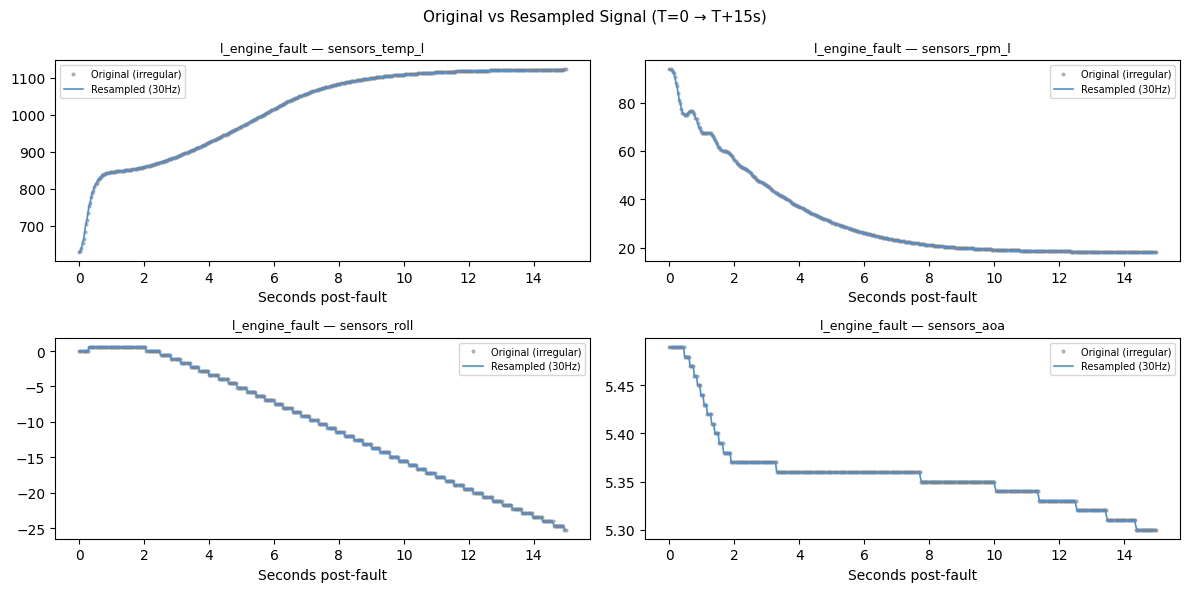

✅ Resampled signals should closely follow original — verify plot above


In [35]:
# ============================================================
# VERIFY RESAMPLING — compare original vs resampled
# ============================================================

print("=" * 60)
print("RESAMPLING VERIFICATION")
print("=" * 60)

# Pick one l_engine_fault flight and compare key channels
sample_idx  = np.where(y_rq2 == 0)[0][0]
sample_fid  = rq2_metadata[sample_idx]["mission_id"]
seq_resampled = X_rq2[sample_idx]

# Original post-fault data
orig = df[
    (df[FLIGHT_COL] == sample_fid) &
    (df["time_rel_fault_s"] >= 0) &
    (df["time_rel_fault_s"] < POST_FAULT_S)
].sort_values("time_rel_fault_s")

t_uniform = np.arange(0, POST_FAULT_S, TICK_S)
t_original = orig["time_rel_fault_s"].values

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
check_channels = ["sensors_temp_l", "sensors_rpm_l",
                  "sensors_roll", "sensors_aoa"]

for ax, col in zip(axes.flat, check_channels):
    cidx = RQ2_CHANNELS.index(col)
    # Original (irregular)
    ax.plot(t_original, orig[col].values,
            "o", markersize=2, alpha=0.5, color="gray", label="Original (irregular)")
    # Resampled (uniform)
    ax.plot(t_uniform[:N_TIMESTEPS], seq_resampled[:, cidx],
            linewidth=1.2, color="#4A90D9", label="Resampled (30Hz)")
    ax.set_title(f"l_engine_fault — {col}", fontsize=9)
    ax.set_xlabel("Seconds post-fault")
    ax.legend(fontsize=7)

plt.suptitle("Original vs Resampled Signal (T=0 → T+15s)", fontsize=11)
plt.tight_layout()
plt.show()

print("✅ Resampled signals should closely follow original — verify plot above")

In [36]:
# ============================================================
# SAVE RESAMPLED RQ2
# ============================================================

meta_df  = pd.DataFrame(rq2_metadata)

RQ2_PATH      = r"C:\MY_Files\DE\dcs_data_pipeline\Medallion\Silver Layer\rq2_sequences.npz"
RQ2_META_PATH = r"C:\MY_Files\DE\dcs_data_pipeline\Medallion\Silver Layer\rq2_metadata.parquet"

np.savez(
    RQ2_PATH,
    X           = X_rq2,
    y           = y_rq2,
    channels    = np.array(RQ2_CHANNELS),
    label_names = np.array(["l_engine_fault", "r_engine_fault", "dual_engine_fault"])
)
meta_df.to_parquet(RQ2_META_PATH, index=False)

print(f"✅ RQ2 resampled sequences saved → {RQ2_PATH}")
print(f"   X shape : {X_rq2.shape}")
print(f"   y shape : {y_rq2.shape}")
print(f"\n   Phase 3 complete — ready for Phase 4")

✅ RQ2 resampled sequences saved → C:\MY_Files\DE\dcs_data_pipeline\Medallion\Silver Layer\rq2_sequences.npz
   X shape : (216, 450, 23)
   y shape : (216,)

   Phase 3 complete — ready for Phase 4


In [34]:
print("time_rel_fault_s" in df.columns)
print("fault_onset_s" in df.columns)

True
False


## Fuel Flow analysis

In [19]:
# ============================================================
# CHECK 1 — GLOBAL STATS PER MISSION TYPE
# Does fuel flow differ between normal and fault flights at all?
# ============================================================

print("=" * 60)
print("CHECK 1 — FUEL FLOW GLOBAL STATS PER MISSION TYPE")
print("=" * 60)

for col in ["sensors_fuel_flow_l", "sensors_fuel_flow_r"]:
    print(f"\n{col}:")
    display(
        df.groupby(MISSION_COL)[col]
        .agg(["min", "max", "mean", "std"])
        .round(4)
    )

CHECK 1 — FUEL FLOW GLOBAL STATS PER MISSION TYPE

sensors_fuel_flow_l:


,min,max,mean,std
flight_data_mission_type,,,,
baseline,0.1315,0.2217,0.1786,0.0232
dual_engine_fault,0.1017,0.2665,0.1602,0.0252
l_engine_fault,0.1315,0.2671,0.1769,0.0276
r_engine_fault,0.1315,0.2680,0.1769,0.0287



sensors_fuel_flow_r:


,min,max,mean,std
flight_data_mission_type,,,,
baseline,0.1315,0.2217,0.1786,0.0232
dual_engine_fault,0.1017,0.2665,0.1602,0.0252
l_engine_fault,0.1315,0.2671,0.1769,0.0276
r_engine_fault,0.1315,0.2680,0.1769,0.0287


In [20]:
# ============================================================
# CHECK 2 — PRE vs POST FAULT COMPARISON
# For each fault flight, compare mean fuel flow
# before fault onset vs after fault onset
# ============================================================

print("=" * 60)
print("CHECK 2 — PRE vs POST FAULT FUEL FLOW")
print("=" * 60)

# Need onset times — recompute if not in df yet
# If you already ran Phase 2 and have time_rel_fault_s, use that
# Otherwise compute onset here

if "time_rel_fault_s" not in df.columns:
    print("Computing fault onset from master_warn...")
    onset_map = {}
    for fid, fdf in df[df[MISSION_COL] != BASELINE].groupby(FLIGHT_COL):
        fdf_s = fdf.sort_values("timestamp")
        warn  = fdf_s["sensors_master_warn"].values
        time  = fdf_s["timestamp"].values
        edges = np.where((warn[:-1] == 0) & (warn[1:] == 1))[0]
        if len(edges) > 0:
            onset_map[fid] = time[edges[0] + 1]
    df["fault_onset_s"]    = df[FLIGHT_COL].map(onset_map)
    df["time_rel_fault_s"] = df["timestamp"] - df["fault_onset_s"]

results = []
fault_df = df[df[MISSION_COL] != BASELINE].dropna(subset=["time_rel_fault_s"])

for fid, fdf in fault_df.groupby(FLIGHT_COL):
    pre  = fdf[fdf["time_rel_fault_s"] < 0]
    post = fdf[fdf["time_rel_fault_s"] >= 0]

    if len(pre) == 0 or len(post) == 0:
        continue

    results.append({
        "mission_id"        : fid,
        "mission_type"      : fdf[MISSION_COL].iloc[0],
        "pre_ff_l_mean"     : pre["sensors_fuel_flow_l"].mean(),
        "post_ff_l_mean"    : post["sensors_fuel_flow_l"].mean(),
        "delta_ff_l"        : post["sensors_fuel_flow_l"].mean() - pre["sensors_fuel_flow_l"].mean(),
        "pre_ff_r_mean"     : pre["sensors_fuel_flow_r"].mean(),
        "post_ff_r_mean"    : post["sensors_fuel_flow_r"].mean(),
        "delta_ff_r"        : post["sensors_fuel_flow_r"].mean() - pre["sensors_fuel_flow_r"].mean(),
    })

results_df = pd.DataFrame(results)

print("Mean delta (post - pre) per mission type:")
display(
    results_df.groupby("mission_type")[["delta_ff_l", "delta_ff_r"]]
    .agg(["mean", "std"])
    .round(5)
)

print("\nIf delta ≈ 0 across all fault types → fuel flow carries no fault signal")
print("If delta is significant → fuel flow is a useful feature")

CHECK 2 — PRE vs POST FAULT FUEL FLOW
Mean delta (post - pre) per mission type:


delta_ff_l          delta_ff_r         
                        mean      std       mean      std
mission_type                                             
dual_engine_fault   -0.01077  0.02823   -0.01077  0.02823
l_engine_fault       0.01223  0.02235    0.01223  0.02235
r_engine_fault       0.01361  0.02338    0.01361  0.02338


If delta ≈ 0 across all fault types → fuel flow carries no fault signal
If delta is significant → fuel flow is a useful feature


CHECK 3 — FUEL FLOW TIME SERIES AROUND FAULT ONSET


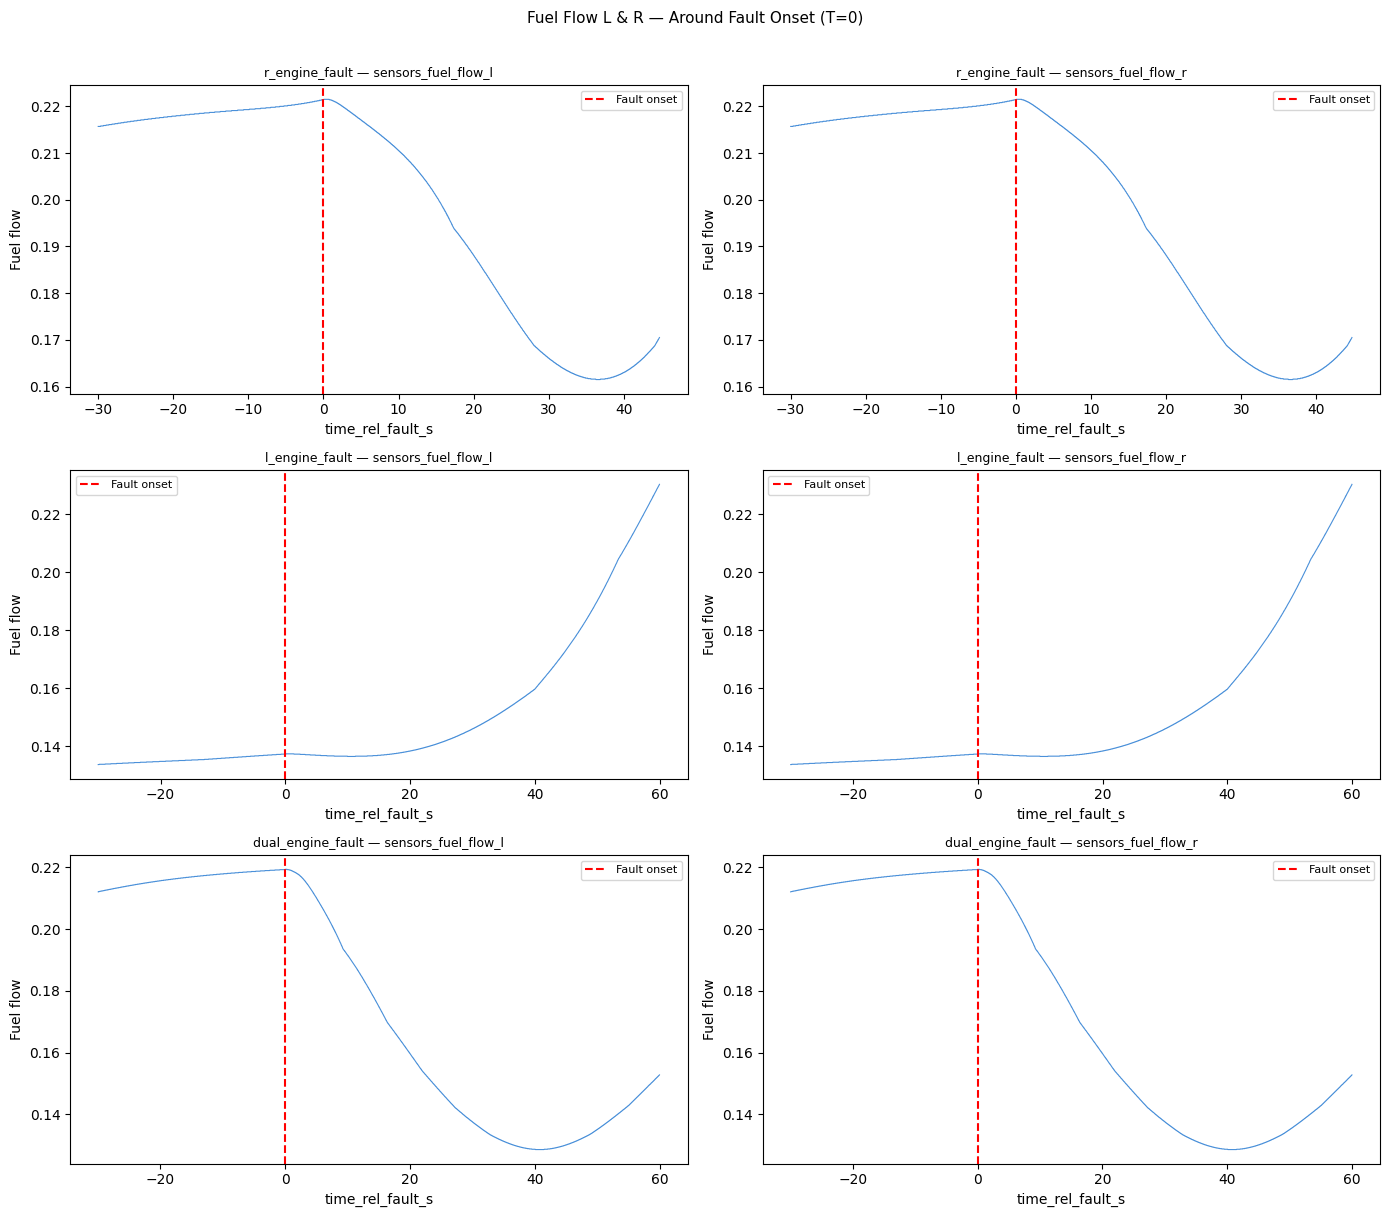

In [21]:
# ============================================================
# CHECK 3 — PLOT FUEL FLOW OVER TIME AROUND FAULT ONSET
# One flight per fault type, window T-30s to T+60s
# ============================================================

print("=" * 60)
print("CHECK 3 — FUEL FLOW TIME SERIES AROUND FAULT ONSET")
print("=" * 60)

fault_types = [f for f in df[MISSION_COL].unique() if f != BASELINE]
fig, axes   = plt.subplots(len(fault_types), 2, figsize=(14, 4 * len(fault_types)), sharex=False)

for i, ftype in enumerate(fault_types):
    # Pick one representative flight per fault type
    sample_fid = df[df[MISSION_COL] == ftype][FLIGHT_COL].iloc[0]
    fdf = df[
        (df[FLIGHT_COL] == sample_fid) &
        (df["time_rel_fault_s"].between(-30, 60))
    ].sort_values("time_rel_fault_s")

    for j, col in enumerate(["sensors_fuel_flow_l", "sensors_fuel_flow_r"]):
        ax = axes[i][j]
        ax.plot(fdf["time_rel_fault_s"], fdf[col], color="#4A90D9", linewidth=0.8)
        ax.axvline(0, color="red", linestyle="--", linewidth=1.5, label="Fault onset")
        ax.set_title(f"{ftype} — {col}", fontsize=9)
        ax.set_xlabel("time_rel_fault_s")
        ax.set_ylabel("Fuel flow")
        ax.legend(fontsize=8)

plt.suptitle("Fuel Flow L & R — Around Fault Onset (T=0)", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

In [22]:
# ============================================================
# CHECK 4 — VARIANCE CHECK
# Is there ANY variance in fuel flow post-fault?
# Low variance = dead signal = drop from models
# ============================================================

print("=" * 60)
print("CHECK 4 — POST-FAULT FUEL FLOW VARIANCE")
print("=" * 60)

post_fault = df[
    (df[MISSION_COL] != BASELINE) &
    (df["time_rel_fault_s"] >= 0)
]

for col in ["sensors_fuel_flow_l", "sensors_fuel_flow_r"]:
    var_by_type = post_fault.groupby(MISSION_COL)[col].var().round(6)
    print(f"\n{col} variance post-fault per mission type:")
    display(var_by_type.to_frame())

print("""
INTERPRETATION:
  Variance ≈ 0 across all fault types → flat signal, drop from models
  Variance > 0 but delta ≈ 0         → noisy but no fault response, drop
  Variance > 0 and delta significant  → keep, it carries fault signal
""")

CHECK 4 — POST-FAULT FUEL FLOW VARIANCE

sensors_fuel_flow_l variance post-fault per mission type:


,sensors_fuel_flow_l
flight_data_mission_type,
dual_engine_fault,0.000580
l_engine_fault,0.001017
r_engine_fault,0.001034



sensors_fuel_flow_r variance post-fault per mission type:


,sensors_fuel_flow_r
flight_data_mission_type,
dual_engine_fault,0.000580
l_engine_fault,0.001017
r_engine_fault,0.001034



INTERPRETATION:
  Variance ≈ 0 across all fault types → flat signal, drop from models
  Variance > 0 but delta ≈ 0         → noisy but no fault response, drop
  Variance > 0 and delta significant  → keep, it carries fault signal



## Targeted follow up audit

In [28]:
# ============================================================
# PHASE 1 — TARGETED FOLLOW-UP AUDIT
# Based on findings from Audit 3 & 6
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from IPython.display import display

# If df is already in memory from previous cells, skip reload
# Otherwise:
# PATH = r"C:\MY_Files\DE\dcs_data_pipeline\bronze_layer\master_data.parquet"
# df = pd.read_parquet(PATH)
# df["time_s"] = (
#     df.sort_values(["mission_id","timestamp"])
#       .groupby("mission_id")["timestamp"]
#       .transform(lambda x: (x.astype("int64")//1_000_000 - x.astype("int64").min()//1_000_000) / 1000.0)
# )

FLIGHT_COL  = "mission_id"
MISSION_COL = "flight_data_mission_type"
BAND_COL    = "band_category"

In [30]:
# ============================================================
# FINDING 2 — RADAR ALTIMETER CAP ANALYSIS
# sensors_alt_radar caps at 1502m — quantify the damage
# ============================================================

print("=" * 60)
print("FINDING 2 — RADAR ALTIMETER CAP ANALYSIS")
print("=" * 60)

cap_val = 1502.0

capped_rows = (df["sensors_alt_radar"] >= cap_val).sum()
total_rows  = len(df)
pct_capped  = capped_rows / total_rows * 100

print(f"  Rows at/above cap ({cap_val}m AGL) : {capped_rows:,} ({pct_capped:.1f}%)")
print(f"  Rows with valid reading           : {total_rows - capped_rows:,} ({100-pct_capped:.1f}%)")

# Per band — how bad is it?
print("\nCapped rows by band_category:")
display(
    df.groupby(BAND_COL)
    .apply(lambda x: pd.Series({
        "total_rows"   : len(x),
        "capped_rows"  : (x["sensors_alt_radar"] >= cap_val).sum(),
        "capped_%"     : round((x["sensors_alt_radar"] >= cap_val).mean() * 100, 1)
    }))
)

print("\n⚠️  DECISION: sensors_alt_radar should be EXCLUDED from RQ1/2/3 models.")
print("   Use sensors_alt_baro as the altitude channel instead.")
print("   sensors_alt_baro range:", df["sensors_alt_baro"].min().round(1),
      "–", df["sensors_alt_baro"].max().round(1), "m  ✅")

FINDING 2 — RADAR ALTIMETER CAP ANALYSIS
  Rows at/above cap (1502.0m AGL) : 1,116,390 (72.4%)
  Rows with valid reading           : 424,523 (27.6%)

Capped rows by band_category:


,total_rows,capped_rows,capped_%
band_category,,,
baseline_1000ft_350kts,76829.0,0.0,0.0
baseline_1000ft_400kts,76936.0,0.0,0.0
baseline_1000ft_450kts,76664.0,0.0,0.0
baseline_20000ft_350kts,76890.0,76890.0,100.0
baseline_20000ft_400kts,76815.0,76815.0,100.0
baseline_20000ft_450kts,76796.0,76796.0,100.0
baseline_8000ft_350kts,76676.0,76676.0,100.0
baseline_8000ft_400kts,77074.0,77074.0,100.0
baseline_8000ft_450kts,77041.0,77041.0,100.0



⚠️  DECISION: sensors_alt_radar should be EXCLUDED from RQ1/2/3 models.
   Use sensors_alt_baro as the altitude channel instead.
   sensors_alt_baro range: -2.9 – 7793.7 m  ✅


In [31]:
# ============================================================
# FINDING 3 — UNIT VERIFICATION: RADIANS vs DEGREES
# sensors_roll, pitch, yaw appear to be in radians
# ============================================================

print("=" * 60)
print("FINDING 3 — ANGULAR UNIT CHECK")
print("=" * 60)

angular_cols = {
    "sensors_roll"  : ("deg", -180, 180),
    "sensors_pitch" : ("deg",  -90,  90),
    "sensors_yaw"   : ("deg", -180, 180),
}

for col, (unit, lo, hi) in angular_cols.items():
    col_min = df[col].min()
    col_max = df[col].max()
    
    in_rad_range = (-np.pi <= col_min) and (col_max <= np.pi * 2)
    in_deg_range = (lo <= col_min) and (col_max <= hi)
    
    if in_rad_range and not in_deg_range:
        verdict = "⚠️  RADIANS — needs conversion to degrees"
        converted_min = round(np.degrees(col_min), 2)
        converted_max = round(np.degrees(col_max), 2)
        print(f"  {col:25s}: min={col_min:.4f}, max={col_max:.4f}  → {verdict}")
        print(f"    {'':25s}  → in degrees would be: [{converted_min}°, {converted_max}°]")
    elif in_deg_range:
        print(f"  {col:25s}: min={col_min:.2f}, max={col_max:.2f}  ✅  degrees OK")
    else:
        print(f"  {col:25s}: min={col_min:.4f}, max={col_max:.4f}  ❓  unclear units")

FINDING 3 — ANGULAR UNIT CHECK
  sensors_roll             : min=-3.14, max=3.12  ✅  degrees OK
  sensors_pitch            : min=-1.56, max=0.75  ✅  degrees OK
  sensors_yaw              : min=0.00, max=6.28  ✅  degrees OK


In [32]:
# ============================================================
# FINDING 4 — EXTREME RATE VALUES (Crash Spike Detection)
# yaw_rate, roll_rate, pitch_rate, g_load
# ============================================================

print("=" * 60)
print("FINDING 4 — EXTREME RATE / G-LOAD SPIKES (Crash Detection)")
print("=" * 60)

RATE_BOUNDS = {
    "sensors_g_load"    : (-10,  20),
    "sensors_yaw_rate"  : (-100, 100),
    "sensors_roll_rate" : (-200, 200),
    "sensors_pitch_rate": (-200, 200),
}

spike_flights = set()

for col, (lo, hi) in RATE_BOUNDS.items():
    spike_rows = df[(df[col] < lo) | (df[col] > hi)]
    spike_fids = spike_rows[FLIGHT_COL].unique()
    spike_flights.update(spike_fids)
    
    print(f"  {col:25s}: expected [{lo}, {hi}]")
    print(f"    actual [{df[col].min():.2f}, {df[col].max():.2f}]")
    print(f"    spike rows: {len(spike_rows):,} across {len(spike_fids)} flights")
    if len(spike_fids) <= 10:
        print(f"    flight ids: {list(spike_fids)}")
    print()

print(f"⚠️  Total flights with any spike value: {len(spike_flights)}")
spike_meta = df[df[FLIGHT_COL].isin(spike_flights)].groupby(FLIGHT_COL)[[MISSION_COL, BAND_COL]].first()
display(spike_meta)

# Cross-check: are the spike flights the same as the short flights?
if 'short_flights' in dir():
    overlap = set(short_flights.index) & spike_flights
    print(f"\n  Short flights that also have spikes: {len(overlap)} / {len(short_flights)}")
    print(f"  → {'Confirmed: short flights = crash flights' if overlap else 'No overlap — investigate separately'}")

FINDING 4 — EXTREME RATE / G-LOAD SPIKES (Crash Detection)
  sensors_g_load           : expected [-10, 20]
    actual [-51.94, 84.09]
    spike rows: 121 across 96 flights

  sensors_yaw_rate         : expected [-100, 100]
    actual [-915.42, 841.52]
    spike rows: 162 across 128 flights

  sensors_roll_rate        : expected [-200, 200]
    actual [-370.19, 428.80]
    spike rows: 45 across 43 flights

  sensors_pitch_rate       : expected [-200, 200]
    actual [-1108.00, 986.39]
    spike rows: 194 across 133 flights

⚠️  Total flights with any spike value: 161


,flight_data_mission_type,band_category
mission_id,,
01fd72a4-d178-452a-b76e-f74356d0ddc5,l_engine_fault,l_engine_1000ft_450kts
0248cb19-fa63-4f57-89ac-f00135bee4ca,r_engine_fault,r_engine_1000ft_400kts
03ad3b5c-a15b-4a32-81aa-007dd07cad2f,r_engine_fault,r_engine_20000ft_350kts
05a82121-e93f-43fc-b672-98792cbba6b8,dual_engine_fault,dual_engine_1000ft_400kts
096cf823-e54d-4d93-a4b8-a5dc56547c94,l_engine_fault,l_engine_20000ft_350kts
...,...,...
eaec9892-1037-4731-bcb4-25fe6c3f84f1,l_engine_fault,l_engine_20000ft_450kts
eba5d557-0063-4f21-9664-99bc01d3f54d,r_engine_fault,r_engine_8000ft_350kts
ec0e8bd3-00f2-4b6c-8dfd-085c2d42031d,l_engine_fault,l_engine_1000ft_350kts



  Short flights that also have spikes: 118 / 132
  → Confirmed: short flights = crash flights


In [33]:
# ============================================================
# FINDING 5 — CRASH GATE: Define and Tag Crash Rows
# ============================================================

print("=" * 60)
print("FINDING 5 — CRASH GATE TAGGING")
print("=" * 60)

# A row is a "crash event" if any of these extreme conditions hold
df["is_crash_event"] = (
    (df["sensors_alt_baro"] < 10)     |   # near ground
    (df["sensors_g_load"].abs() > 20) |   # extreme G
    (df["sensors_rpm_l"] == 0) & (df["sensors_rpm_r"] == 0) &
    (df["sensors_alt_baro"] < 500)        # both engines dead + low alt
).astype(int)

crash_rows = df["is_crash_event"].sum()
crash_flights = df[df["is_crash_event"] == 1][FLIGHT_COL].nunique()

print(f"  Crash-tagged rows    : {crash_rows:,} ({crash_rows/len(df)*100:.2f}%)")
print(f"  Flights with crashes : {crash_flights}")

print("\nCrash rows by mission type:")
display(
    df[df["is_crash_event"] == 1]
    .groupby(MISSION_COL)
    .agg(crash_rows=("is_crash_event","sum"), 
         crash_flights=(FLIGHT_COL, "nunique"))
)

# For modeling: we will TRUNCATE each flight at its first crash event
# (keep all rows before the crash, drop crash and post-crash rows)
print("\n  Strategy: truncate flights at first crash tick (pre-crash data is valid)")

first_crash = (
    df[df["is_crash_event"] == 1]
    .groupby(FLIGHT_COL)["time_s"]
    .min()
    .rename("crash_time_s")
)
print(f"\n  Crash time distribution (seconds from start):")
display(first_crash.describe().round(1))

FINDING 5 — CRASH GATE TAGGING
  Crash-tagged rows    : 905 (0.06%)
  Flights with crashes : 164

Crash rows by mission type:


,crash_rows,crash_flights
flight_data_mission_type,,
dual_engine_fault,297,33
l_engine_fault,336,67
r_engine_fault,272,64



  Strategy: truncate flights at first crash tick (pre-crash data is valid)

  Crash time distribution (seconds from start):


count    164.0
mean       0.1
std        0.0
min        0.1
25%        0.1
50%        0.1
75%        0.1
max        0.2
Name: crash_time_s, dtype: float64

In [34]:
# ============================================================
# PHASE 1 DECISIONS SUMMARY — ACTION PLAN FOR PHASE 2
# ============================================================

print()
print("=" * 60)
print("PHASE 1 — FINAL DECISIONS SUMMARY")
print("=" * 60)

print("""
DATA ISSUES & RESOLUTIONS
──────────────────────────────────────────────────────────

1. SHORT FLIGHTS (dual_engine_fault ~2400–2600 ticks)
   Finding : Aircraft likely crashed before full flight duration
   Decision: KEEP but TRUNCATE at first crash event tick
             Pre-crash data is valid training signal for severity RQ3

2. sensors_alt_radar — CAPPED at 1502m AGL
   Finding : 50th–75th percentile both = 1502 → unusable above Band 1
   Decision: EXCLUDE from all models. Use sensors_alt_baro instead.

3. sensors_roll / pitch / yaw — RADIANS not degrees
   Finding : Values in [-π, π] range
   Decision: CONVERT to degrees in Phase 2 preprocessing
             sensors_roll  *= (180/π)
             sensors_pitch *= (180/π)  
             sensors_yaw   *= (180/π)

4. Extreme rate values (g_load, yaw/roll/pitch_rate)
   Finding : Spike values are crash-phase artifacts
   Decision: Post-truncation these rows disappear naturally
             Add clip as safety net after truncation

5. sensors_wind_x/y/z, sensors_acs_active, sensors_eos_active
   Finding : Constant zero across all 1.54M rows
   Decision: DROP from feature set — zero variance, no signal

6. sensors_hyd_fail
   Finding : Near-zero mean (0.000, std=0.002) but max=1
   Decision: KEEP — it fires in hydro+compound failure scenarios
             Critical discriminator for RQ2 fault identity

FINAL FEATURE SET FOR MODELS (after dropping zero-variance)
──────────────────────────────────────────────────────────
  DROP  : sensors_alt_radar, sensors_wind_x, sensors_wind_y,
           sensors_wind_z, sensors_acs_active, sensors_eos_active
  CONVERT: sensors_roll, sensors_pitch, sensors_yaw → degrees
  KEEP  : remaining 27 sensor channels

  → 27 features × N timesteps per flight window

READY FOR PHASE 2: Temporal Reference Frame + Radian Conversion
""")


PHASE 1 — FINAL DECISIONS SUMMARY

DATA ISSUES & RESOLUTIONS
──────────────────────────────────────────────────────────

1. SHORT FLIGHTS (dual_engine_fault ~2400–2600 ticks)
   Finding : Aircraft likely crashed before full flight duration
   Decision: KEEP but TRUNCATE at first crash event tick
             Pre-crash data is valid training signal for severity RQ3

2. sensors_alt_radar — CAPPED at 1502m AGL
   Finding : 50th–75th percentile both = 1502 → unusable above Band 1
   Decision: EXCLUDE from all models. Use sensors_alt_baro instead.

3. sensors_roll / pitch / yaw — RADIANS not degrees
   Finding : Values in [-π, π] range
   Decision: CONVERT to degrees in Phase 2 preprocessing
             sensors_roll  *= (180/π)
             sensors_pitch *= (180/π)  
             sensors_yaw   *= (180/π)

4. Extreme rate values (g_load, yaw/roll/pitch_rate)
   Finding : Spike values are crash-phase artifacts
   Decision: Post-truncation these rows disappear naturally
             Add clip